# Feature Importance Analyses for Mislocalized Variants

We select for the interpretable CellProfiler features that contribute most significantly in the XGBoost Classifier to help distinguish the mislocalized variants from their respective reference alleles.

In [1]:
import os
import polars as pl
import seaborn as sns
from adjustText import adjust_text
from sklearn.decomposition import PCA
import umap
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
from functools import reduce
import operator
from tqdm import tqdm

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

# controls = {
#     "TC": ["EGFP"],
#     "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
#     "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
#     # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
#     # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
#     # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
#     # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
# }
# ctrl_alleles = [k_v for k_v in controls.values()]
# ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
# # ctrl_alleles_flat

np.random.seed(42)
random.seed(42)

## 1. Load feature importance and classifier info

### 1.1 Feature importance for each variant

In [2]:
## classification results in SM pipeline
SM_CLASS_RES_DIR = CLASS_RESULTS_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells"
FEAT = "GFP"
MISLOCALIZED_LABEL = "Altered_95th_perc_both_batches_GFP"

In [3]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col(MISLOCALIZED_LABEL)==1
)
allele_list = list(imaging_summary_clinvar["gene_allele"]) + list(imaging_summary_clinvar["Gene"].unique())
hits_allele_list = list(imaging_summary_clinvar_hits["gene_allele"]) + list(imaging_summary_clinvar_hits["Gene"].unique())
bio_reps = list(imaging_summary_clinvar_hits["Metadata_Bio_Batch"].unique())

In [4]:
imaging_summary_clinvar_hits

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,…,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category
str,str,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,i64,f64,str,…,f64,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,f64,str,str,str,i64,str,f64,f64,str,str
"""SMARCB1""","""SMARCB1_Pro48Leu""",-4.744349,0.002097,-10.576204,0.000015,"""2025_03_Batch_15-16""",true,true,true,true,true,true,true,false,true,true,0.996378,0.992405,0.984188,0.988582,0.962704,0.936465,0.981221,0.977555,0.988163,0.994737,0.988943,0.995942,0.990821,0.996648,0.998018,"""SMARCB1""","""ENSG00000099956""",53965,204888.0,"""CCSBVarC005063""",…,2.3791805e7,"""22q11.23""","""criteria provided, single subm…",2.0,"""-""","""N""","""ClinGen:CA129018,OMIM:601607.0…",3.0,30202.0,2.3791805e7,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV001512543""","""-""","""-""","""143C>T ""","""Pro48Leu""","""NM_003073.5""",1.0,"""4_VUS""",92.49,0.433824,"""['162091']""","""autosomal dominant""","""Rare genetic developmental def…",5,"""SCHWANNOMATOSIS 1""",92.49,0.433824,"""10-90""",""">90"""
"""MVK""","""MVK_Leu265Pro""",-3.469454,0.032036,-6.561184,0.010338,"""2024_12_Batch_11-12""",true,true,true,true,false,true,true,false,true,false,0.9921,0.991156,0.972623,0.987362,0.933829,0.957179,0.987779,0.972903,0.991911,0.991815,0.910479,0.986946,0.972343,0.990401,0.992385,"""MVK""","""ENSG00000110921""",281,200099.0,"""CCSBVarC004842""",…,1.09591266e8,"""12q24.11""","""no classification provided""",1.0,"""-""","""N""","""ClinGen:CA149901,UniProtKB:Q03…",2.0,97626.0,1.09591266e8,"""T""","""C""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000115983""","""-""","""-""","""794T>C ""","""Leu265Pro""","""NM_000431.4""",null,"""5_Others""",98.29,0.02439,"""['260920']""","""autosomal recessive""","""Rare genetic systemic or rheum…",6,"""HYPER-IgD SYNDROME""",98.29,0.02439,"""<10""",""">90"""
"""KRT8""","""KRT8_Arg454Cys""",-1.583367,0.164427,-2.806288,0.026286,"""2024_01_Batch_7-8""",true,false,false,false,false,false,false,false,false,false,0.979169,0.909544,0.952069,0.930835,0.771028,0.943884,0.971474,0.984433,0.972406,0.993686,0.598172,0.890197,0.919704,0.846683,0.964652,"""KRT8""","""ENSG00000170421""",14966,218520.0,"""CCSBVarC004269""",…,5.289752e7,"""12q13.13""","""no classification provided""",1.0,"""-""","""N""",""

### 1.2 Select for the CP features with importance > 1e-3 for each variant

In [5]:
# feat_import_df_feat = pl.DataFrame()
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         # Read the data
#         feat_df = pl.scan_csv(f"{SM_CLASS_RES_DIR.format(batch_id=batch_id)}/feat_importance.csv")
#         meta_cols = [c for c in feat_df.collect_schema().names() if c.startswith("Metadata_") or c.startswith("Group") or c == "Batch"]
#         feat_cols = [c for c in feat_df.collect_schema().names() if c not in meta_cols and FEAT in c]
#         feat_df_batch = feat_df.with_columns(
#             [pl.col(c).cast(pl.Float64, strict=False).alias(c) for c in feat_cols]
#         ).with_columns(
#             pl.lit(batch_id).alias("Metadata_Batch"),
#             pl.col("Group2").str.split('_').list.slice(-2).list.join("_").alias("Metadata_gene_allele")
#        ).filter(
#             (pl.col("Metadata_Feature_Type")==FEAT)&(~pl.col("Metadata_Control"))
#             &(pl.col("Group1").is_in(allele_list)|(pl.col("Metadata_gene_allele").is_in(batch_allele_list)))
#         ).select(meta_cols + feat_cols + ["Metadata_Batch", "Metadata_gene_allele"])
#         feat_import_df_feat = pl.concat([feat_import_df_feat, feat_df_batch.collect()], how="diagonal")

In [6]:
# key_alleles_df = imaging_summary_clinvar.to_pandas()
# feat_df = pl.DataFrame()
# importance_thres = 1e-3
# # top_num = 5

# for j, allele in tqdm(key_alleles_df.iterrows()):
#     batch_list = list(feat_import_df_feat.filter(
#         pl.col("Metadata_gene_allele")==allele["gene_allele"]
#     ).unique("Metadata_Batch")["Metadata_Batch"])
#     allele_df = pl.DataFrame()
#     for i, batch in enumerate(batch_list):
#         batch_df = feat_import_df_feat.filter(
#             (pl.col("Metadata_Batch")==batch)&(pl.col("Metadata_gene_allele")==allele["gene_allele"])
#         )
#         feat_cols = [col for col in batch_df.columns if "Metadata" not in col and "Group" not in col]
#         batch_df = batch_df.filter(
#             ~pl.all_horizontal(pl.col(feat_cols).is_null())
#         )
#         non_null_gfp = [col for col in feat_cols if not batch_df[col].is_null().any()]
#         batch_df_col = (
#             batch_df.select(non_null_gfp).mean()
#            .transpose(include_header=True)
#            .filter(pl.col("column_0") > importance_thres)
#            .sort("column_0", descending=True)
#            # .head(top_num)#["column"]
#            # .to_list()
#         )
#         if not allele_df.is_empty():
#             allele_df = allele_df.join(
#                 batch_df_col.with_columns(
#                     pl.col("column_0").alias(batch),
#                     pl.col("column").alias("index"),
#                 ).select("index", batch),
#                 on="index",
#                 how="full",
#                 coalesce=True
#             )
#         else:
#             allele_df = batch_df_col.with_columns(
#                 pl.col("column_0").alias(batch),
#                 pl.col("column").alias("index"),
#             ).select("index", batch)
            
#     allele_df = allele_df.with_columns(
#         pl.mean_horizontal(pl.col([col for col in allele_df.columns if "Batch" in col])).alias("feat_importance"),
#         pl.col("index").alias("cp_feature")
#     ).select(
#         pl.col(["cp_feature", "feat_importance"])
#     ).rename(
#         {"feat_importance": allele["gene_allele"]}
#     )
#     if not feat_df.is_empty():
#         feat_df = feat_df.join(
#             allele_df,
#             left_on="cp_feature",
#             right_on="cp_feature",
#             how="full",
#             coalesce=True
#         )
#     else:
#         feat_df = allele_df

915it [02:45,  5.54it/s]


In [8]:
# feat_df.write_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

### 1.3 Load CellProfiler features

#### Loading QC info per each imaging well

In [60]:
## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

feat_df = pl.read_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")
feat_df.shape

feat_df

cp_feature,DCX_Thr203Arg,AGXT_Pro319Leu,CTH_Gln240Glu,SMARCB1_Pro48Leu,MVK_Leu265Pro,KRT8_Arg454Cys,THAP1_Val193Ile,DES_Asn342Asp,MVK_Pro200Ser,KCTD7_Asp115Tyr,TPK1_Asn50His,LITAF_Pro84Leu,TH_Gln39Glu,AP2S1_Arg15Cys,DES_Asp312Ala,FBP1_Pro284Arg,AGXT_Ser218Leu,AGXT_Pro11Leu,DES_Arg127Pro,APOA1_Arg34Leu,MVK_Arg106His,SMAD3_Cys109Tyr,MLH1_Lys670Arg,LITAF_Ala111Gly,TPM1_Asp230Asn,KCNJ2_Asp71His,EMD_Pro183Thr,GFAP_Lys236Thr,MLH1_Ala29Gly,GFAP_Glu205Lys,KCNJ2_Met301Leu,GRN_Ala324Thr,TPM1_Met8Arg,GFAP_Arg79Ser,MLH1_Pro640Ser,KCNJ2_Val93Ile,…,FH_Pro174Arg,BRIP1_Gln255His,ABCD1_Arg389Gly,F9_Asp110Asn,BRCA1_Thr587Arg,RAF1_Asp486Asn,F9_Asp110Gly,CTCF_Arg342Cys,FARS2_His135Asp,SHOC2_Ser2Gly,RAF1_Asn71Ser,ZC4H2_Ile7Val,LMNA_Arg349Leu,FH_Arg233Leu,F9_Glu73Val,F9_Arg384Leu,BRIP1_Leu195Pro,RET_Arg67His,FARS2_Ile329Thr,F9_Phe395Ile,BRAF_Val487Gly,RAF1_Ser427Gly,BRCA1_Ala102Gly,SDHD_Leu107Pro,BRCA1_Cys64Tyr,FH_Gln376Pro,F9_Glu73Lys,BRCA1_Arg595Gln,BCL10_Leu8Leu,BRIP1_Val76Ile,BAP1_Cys91Gly,SHOC2_Thr321Ala,BRCA1_Cys39Arg,SDHD_Ile31Val,RAD51D_Met308Val,FANCC_Leu554Pro,SHOC2_Leu174Phe
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Cytoplasm_Intensity_MinIntensi…",0.012122,0.023753,null,null,0.016431,0.010715,0.008461,0.004437,0.007889,0.005248,0.017127,null,0.00971,null,0.010829,0.002916,0.007031,0.01341,0.005683,null,0.006153,null,null,null,null,null,0.005684,null,null,null,null,0.011789,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.007939,null,null,null,null,null,null,null,null
"""Cells_Correlation_RWC_Mito_GFP""",0.009749,0.014136,0.016764,0.004104,0.015118,0.007607,0.008516,0.012526,0.009758,0.010591,0.012717,0.006805,0.007884,0.015078,0.007223,0.006405,0.005975,0.008901,0.015653,0.0075,0.012423,0.01013,null,0.010576,0.007596,0.006794,0.011212,0.010473,null,0.007091,0.00755,0.008291,0.007371,0.010529,null,0.005254,…,0.009972,0.007912,0.009192,0.005965,0.005315,0.007573,0.005242,0.006904,0.007391,0.015597,0.006394,0.021398,0.00482,0.006564,0.005271,0.011706,0.005215,0.007863,0.007923,0.048851,0.007624,0.008324,0.027198,0.023254,0.013457,0.004748,0.004619,0.005168,0.004925,0.006632,0.014377,0.006037,0.004625,0.009004,0.007289,0.003605,0.014254
"""Nuclei_Correlation_K_GFP_AGP""",0.01481,0.011137,0.010551,0.010761,0.0053,0.009562,0.017072,0.016377,0.009425,0.009203,0.010362,0.00385,0.005028,0.009542,0.005634,0.004209,0.011593,0.010526,0.009356,0.006146,0.009015,0.007634,0.018528,0.006277,0.015655,0.004142,0.019903,0.007018,0.020791,0.006597,0.005301,0.014914,0.015133,0.007143,0.015652,0.007521,…,0.004693,0.015002,0.005679,0.008433,0.005495,0.00788,0.005269,0.005264,0.010453,0.009003,0.007517,0.0324,0.007642,0.007132,0.007083,0.007385,0.012052,0.009882,0.010941,0.005515,0.010283,0.018335,0.004924,0.01209,0.013003,0.04825,0.014047,0.005076,0.010488,0.013382,0.010893,0.020522,0.007888,0.011524,0.009266,0.007821,0.014535
"""Cytoplasm_Intensity_MaxIntensi…",0.01349,0.020752,0.012222,0.003882,0.035819,0.011329,0.00858,0.009624,0.00842,0.005682,0.033607,0.121668,0.018619,0.016554,0.007506,0.153167,0.005316,0.007247,0.020411,0.011229,0.009466,0.02223,null,0.017161,0.0084,0.004825,0.038299,0.007795,null,0.008935,0.00528,0.019288,0.009113,0.009608,null,0.007854,…,0.021116,0.00603,0.006139,0.006888,0.015616,0.025588,0.003067,0.013374,0.008916,0.028845,0.024105,0.013732,0.008792,0.005762,0.00973,0.00821,0.00448,0.007227,0.008895,0.008777,0.010294,0.062097,0.027416,0.014365,0.007079,0.02152,0.008066,0.013231,0.007231,0.005402,0.007021,0.006184,0.011647,0.005257,0.078933,0.013309,0.071563
"""Cells_RadialDistribution_MeanF…",0.007249,0.009872,0.005171,0.008969,0.019083,0.005332,0.009445,0.005668,0

In [58]:
allele_meta_df = pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}

for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
            # display(allele_meta_df.head())
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

#### Load the features from the valid cells only

In [59]:
# Paths
ref_var_cell_qc_prof_df = pl.DataFrame()
target_gene_alleles = []
meta_cols = [
    "Metadata_CellID",
    "Metadata_gene_allele",
    "Metadata_Well",
    "Metadata_Plate",
    "Metadata_node_type"
]

# Get meta features
for bio_rep in bio_reps:
    bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
    ## ONLY grep the allele come from the bio-rep
    allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
    batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
    for batch_id in bio_rep_batches:
        batch_alleles = (
            pl.scan_parquet(
                PASS_QC_PROF_PQ.format(batch_id=batch_id)
            )
            .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
            .with_columns(
                pl.concat_str(
                    [
                        "Metadata_Plate",
                        "Metadata_Well",
                        "Metadata_ImageNumber",
                        "Metadata_ObjectNumber",
                    ],
                    separator="_",
                ).alias("Metadata_CellID")
            )
        ).collect()
        # feat_cols = [col for col in batch_alleles.columns if ("AGP".lower() in col.lower() or "DNA".lower() in col.lower() or "Mito".lower() in col.lower()) and ("GFP".lower() not in col.lower())]
        batch_alleles = batch_alleles.join(
            img_well_qc_sum_dict[bio_rep].filter(pl.col("channel")==FEAT).select(pl.col("plate", "well", "is_bg")),
            left_on=["Metadata_Plate", "Metadata_Well"],
            right_on=["plate", "well"]
        ).filter(
            ~pl.col("is_bg")
        ).select(pl.col(meta_cols))
        ref_var_cell_qc_prof_df = pl.concat([ref_var_cell_qc_prof_df, batch_alleles], how="diagonal_relaxed")

#### Load all the features available

In [62]:
# # Paths
# ref_var_cell_all_prof_list = []
# for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = list(allele_batch_df["gene_allele"]) + list(allele_batch_df["Gene"].unique())
#     for batch_id in bio_rep_batches:
#         batch_alleles = (
#             pl.scan_parquet(
#                 ALL_PROF_QC.format(batch_id=batch_id)
#             )
#             .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
#             .with_columns(
#                 pl.concat_str(
#                     [
#                         "Metadata_Plate",
#                         "Metadata_Well",
#                         "Metadata_ImageNumber",
#                         "Metadata_ObjectNumber",
#                     ],
#                     separator="_",
#                 ).alias("Metadata_CellID")
#             )
#         )
#         ref_var_cell_all_prof_list.append(batch_alleles)

# # all_feat_cols = reduce(set.intersection, map(set, [[col for col in ref_var_cell_all_prof.collect_schema() if (FEAT.lower() in col.lower()) and ("Brightfield".lower() not in col.lower())] for ref_var_cell_all_prof in ref_var_cell_all_prof_list]))
# # select_cols = list(all_feat_cols) + ["Metadata_CellID"]
# # ref_var_cell_all_prof_df = pl.concat([batch_alleles.select(select_cols).collect() for batch_alleles in ref_var_cell_all_prof_list])

# select_cols = ["Metadata_CellID"] + list(feat_df["cp_feature"])
# ref_var_cell_all_prof_df = pl.concat(
#     [batch_alleles.select([c for c in select_cols if c in batch_alleles.collect_schema()]).collect() for batch_alleles in ref_var_cell_all_prof_list],
#     how="diagonal"
# )
# # This method of joining ensures that only cells past filters are included in the abundance analysis
# ref_var_cell_all_prof_df = ref_var_cell_qc_prof_df.join(ref_var_cell_all_prof_df, 
#                                                         on="Metadata_CellID", 
#                                                         how="left", coalesce=True)
# # ref_var_cell_all_prof_df.write_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_sig_feat_sc_cp_profiles.parquet")

In [65]:
ref_var_cell_all_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_sig_feat_sc_cp_profiles.parquet")

In [69]:
# ref_var_cell_all_prof_df.unique("Metadata_gene_allele")

In [66]:
ref_var_cell_all_prof_df

Metadata_CellID,Metadata_gene_allele,Metadata_Well,Metadata_Plate,Metadata_node_type,Cytoplasm_Intensity_MinIntensity_GFP,Cells_Correlation_RWC_Mito_GFP,Nuclei_Correlation_K_GFP_AGP,Cytoplasm_Intensity_MaxIntensity_GFP,Cells_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_K_GFP_Mito,Nuclei_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_RWC_GFP_DNA,Nuclei_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_Correlation_RWC_DNA_GFP,Nuclei_Texture_SumAverage_GFP_20_00_256,Cytoplasm_Texture_SumAverage_GFP_20_00_256,Cytoplasm_Granularity_1_GFP,Nuclei_Correlation_RWC_GFP_AGP,Cells_Correlation_RWC_DNA_GFP,Nuclei_Correlation_RWC_AGP_GFP,Cells_RadialDistribution_FracAtD_GFP_7of10,Nuclei_Correlation_Overlap_AGP_GFP,Nuclei_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_DNA_GFP,Cytoplasm_Texture_InfoMeas1_GFP_5_03_256,Cells_Texture_DifferenceVariance_GFP_20_01_256,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_Texture_Correlation_GFP_20_00_256,Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,Cells_Texture_InverseDifferenceMoment_GFP_20_03_256,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Cytoplasm_Granularity_4_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cells_Correlation_RWC_GFP_Mito,…,Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256,Cytoplasm_Texture_InfoMeas2_GFP_10_03_256,Nuclei_Granularity_6_GFP,Nuclei_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_InverseDifferenceMoment_GFP_10_01_256,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cytoplasm_Texture_InfoMeas1_GFP_20_00_256,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cells_Texture_InfoMeas1_GFP_10_01_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cells_Granularity_3_GFP,Nuclei_Texture_InfoMeas2_GFP_5_00_256,Cells_Texture_Entropy_GFP_5_00_256,Cells_Texture_InfoMeas2_GFP_5_02_256,Nuclei_Texture_Correlation_GFP_10_03_256,Cytoplasm_RadialDistribution_FracAtD_GFP_6of10,Cells_Intensity_MinIntensityEdge_GFP,Nuclei_RadialDistribution_MeanFrac_GFP_7of10,Cells_Texture_SumAverage_GFP_5_00_256,Cytoplasm_Texture_Entropy_GFP_20_03_256,Nuclei_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_20_01_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_00_256,Nuclei_Correlation_K_GFP_DNA,Nuclei_Correlation_Overlap_DNA_GFP,Cells_Correlation_Overlap_AGP_GFP,Cytoplasm_Correlation_Overlap_AGP_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cells_Correlation_K_GFP_AGP,Cells_Correlation_Manders_AGP_GFP,Cells_Correlation_Manders_DNA_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Nuclei_Texture_SumAverage_GFP_5_03_256,Nuclei_Texture_SumAverage_GFP_5_01_256
str,str,str,str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""2024_01_17_B7A1R1_P1T1_H12_161…","""DES_Ala337Pro""","""H12""","""2024_01_17_B7A1R1_P1T1""","""allele""",-0.808281,1.167092,1.584441,-0.675784,0.669413,4.590006,-0.276015,0.961843,-0.348344,-1.140486,1.017131,-0.19032,-0.897382,0.974739,0.276066,1.206225,0.749458,0.340626,0.062728,1.138775,0.508529,-0.662162,0.642349,7.47651,-0.102504,-0.746183,-0.137717,1.112812,0.752184,1.89097,-0.163979,0.131115,…,0.93044,-0.759747,-0.720445,-0.67205,0.920894,-1.015579,0.997956,-0.7456,0.519719,3.724244,0.92623,0.662969,2.498522,-0.898923,-0.813634,-2.016749,-0.065581,-0.559141,-0.482734,0.34322,-0.94608,-0.968655,1.021588,6.925316,0.945958,0.797526,null,null,null,null,null,null,null,null,null,null,null
"""2024_01_17_B7A1R1_P1T1_L17_252…","""DCX_Pro191Arg""","""L17""","""2024_01_17_B7A1R1_P1T1""","""allele""",1.378111,1.372456,-0.953492,1.058461,-0.394987,-0.670084,-1.523271,0.294872,2.447483,-0.01748

In [76]:
norm_vars_feat_df = pl.DataFrame()
sig_diff_feat = list(feat_df["cp_feature"])

for gene in tqdm(imaging_summary_clinvar["Gene"].unique()):
    gene_mean = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).mean().to_numpy()
    gene_std = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).std().to_numpy()
    var_feat_df = ref_var_cell_all_prof_df.filter(
        (pl.col("Metadata_gene_allele").str.contains(gene))&(pl.col("Metadata_gene_allele")!=gene)
    ).group_by(
        "Metadata_gene_allele"
    ).agg(
        pl.col(col).median().alias(col)
        for col in ref_var_cell_all_prof_df.columns
        if not col.startswith("Metadata_")
    ).to_pandas().set_index("Metadata_gene_allele")[sig_diff_feat]
    norm_gene_var_feat_df = (var_feat_df - gene_mean) / gene_std
    norm_vars_feat_df = pl.concat([norm_vars_feat_df, pl.DataFrame(norm_gene_var_feat_df.reset_index())], how="diagonal")

100%|██████████| 131/131 [00:25<00:00,  5.20it/s]


In [77]:
norm_vars_feat_df

Metadata_gene_allele,Cytoplasm_Intensity_MinIntensity_GFP,Cells_Correlation_RWC_Mito_GFP,Nuclei_Correlation_K_GFP_AGP,Cytoplasm_Intensity_MaxIntensity_GFP,Cells_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_K_GFP_Mito,Nuclei_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_RWC_GFP_DNA,Nuclei_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_Correlation_RWC_DNA_GFP,Nuclei_Texture_SumAverage_GFP_20_00_256,Cytoplasm_Texture_SumAverage_GFP_20_00_256,Cytoplasm_Granularity_1_GFP,Nuclei_Correlation_RWC_GFP_AGP,Cells_Correlation_RWC_DNA_GFP,Nuclei_Correlation_RWC_AGP_GFP,Cells_RadialDistribution_FracAtD_GFP_7of10,Nuclei_Correlation_Overlap_AGP_GFP,Nuclei_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_DNA_GFP,Cytoplasm_Texture_InfoMeas1_GFP_5_03_256,Cells_Texture_DifferenceVariance_GFP_20_01_256,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_Texture_Correlation_GFP_20_00_256,Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,Cells_Texture_InverseDifferenceMoment_GFP_20_03_256,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Cytoplasm_Granularity_4_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cells_Correlation_RWC_GFP_Mito,Cytoplasm_Granularity_2_GFP,Nuclei_RadialDistribution_FracAtD_GFP_5of10,Cells_Correlation_Manders_GFP_Mito,Cells_RadialDistribution_MeanFrac_GFP_7of10,…,Nuclei_Granularity_5_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_4of10,Cytoplasm_Texture_AngularSecondMoment_GFP_5_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_10_01_256,Cytoplasm_Intensity_MinIntensityEdge_GFP,Nuclei_RadialDistribution_FracAtD_GFP_4of10,Cytoplasm_RadialDistribution_RadialCV_GFP_4of10,Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256,Cytoplasm_Texture_InfoMeas2_GFP_10_03_256,Nuclei_Granularity_6_GFP,Nuclei_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_InverseDifferenceMoment_GFP_10_01_256,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cytoplasm_Texture_InfoMeas1_GFP_20_00_256,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cells_Texture_InfoMeas1_GFP_10_01_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cells_Correlation_Manders_AGP_GFP,Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cells_Granularity_3_GFP,Nuclei_Texture_SumAverage_GFP_5_01_256,Nuclei_Texture_InfoMeas2_GFP_5_00_256,Cells_Texture_Entropy_GFP_5_00_256,Cells_Texture_InfoMeas2_GFP_5_02_256,Nuclei_Texture_Correlation_GFP_10_03_256,Cytoplasm_RadialDistribution_FracAtD_GFP_6of10,Cells_Intensity_MinIntensityEdge_GFP,Cells_Correlation_Manders_DNA_GFP,Nuclei_RadialDistribution_MeanFrac_GFP_7of10,Cells_Texture_SumAverage_GFP_5_00_256,Cytoplasm_Texture_Entropy_GFP_20_03_256,Cytoplasm_Correlation_Manders_AGP_GFP,Nuclei_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_20_01_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_00_256
str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""SDC3_Val136Ile""",0.000441,-0.160492,-0.591632,-0.140556,0.256895,0.557707,-0.092027,0.08093,-0.402516,0.468626,0.406421,0.164571,0.184297,0.026028,0.372112,0.221246,0.343048,0.214183,0.391548,-0.149167,-0.072991,-0.377888,0.255206,0.000751,-0.165462,0.429049,-0.139728,0.285393,-0.210799,-0.367313,-0.023698,0.160288,-0.197494,0.227529,0.43017,-0.277391,…,-0.544408,-0.185563,0.030599,0.003237,-0.003564,0.193938,-0.199039,0.358245,-0.243683,-0.590263,0.12395,0.256471,-0.087028,0.16996,-0.223035,0.184999,0.150616,null,0.171454,0.169352,-0.228632,null,-0.208537,-0.218076,-0.183872,0.536756,-0.080485,-0.003161,null,0.09936,-0.007987,-0.224839,null,0.543934,0.039528,0.310144,0.228675
"""RP2_Leu253Arg""",-0.790027,-0.064547,2.126156,-1.0

In [78]:
## remove corr features
norm_vars_feat_select_df = feature_select(norm_vars_feat_df.to_pandas(), operation="variance_threshold")
norm_vars_feat_select_df = feature_select(norm_vars_feat_select_df, operation="correlation_threshold")

In [79]:
norm_vars_feat_select_df

,Metadata_gene_allele,Cells_Correlation_RWC_Mito_GFP,Cytoplasm_Intensity_MaxIntensity_GFP,Nuclei_Correlation_K_GFP_Mito,Nuclei_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_RWC_GFP_DNA,Nuclei_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Nuclei_Correlation_RWC_GFP_AGP,Cells_RadialDistribution_FracAtD_GFP_7of10,...,Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256,Nuclei_Granularity_6_GFP,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cells_Granularity_3_GFP,Cells_Intensity_MinIntensityEdge_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Nuclei_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_00_256
0,SDC3_Val136Ile,-0.160492,-0.140556,0.557707,-0.092027,0.080930,-0.402516,0.468626,0.372112,0.214183,...,0.358245,-0.590263,-0.087028,-0.223035,0.150616,-0.228632,-0.003161,NaN,0.543934,0.310144
1,RP2_Leu253Arg,-0.064547,-1.090864,2.050605,-0.014207,0.189696,0.643868,0.405943,0.239993,0.530370,...,1.160329,-0.004959,0.099514,-1.731587,2.450128,-0.117954,-0.850797,NaN,1.036206,1.768970
2,RP2_Arg282Trp,0.082656,-0.028588,-0.371819,-0.218479,0.259279,-0.114731,0.048105,0.242535,0.022391,...,0.064117,-0.248969,-0.207327,0.103439,-0.373155,-0.301487,-0.193205,NaN,0.113791,-0.028559
3,RP2_Cys86Tyr,0.061934,-1.103215,1.175555,0.154386,0.224714,0.418535,0.498122,0.340047,0.346611,...,1.178114,-0.006576,-0.104941,-1.750169,2.315112,-0.041980,-0.852398,NaN,1.060249,1.783414
4,RP2_Arg118His,0.132634,-0.152260,-0.359679,-0.194286,0.205818,-0.161909,0.124236,0.266632,-0.056042,...,0.053814,-0.248969,-0.237453,0.018263,-0.317441,-0.298549,-0.201767,NaN,0.150254,0.047099
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
912,KRAS_Thr58Ile,0.373242,-0.231977,-0.261894,-0.234202,0.176101,0.346962,-0.097655,0.278156,0.123035,...,0.053535,-0.162904,-0.057923,-0.003688,-0.498739,-0.138501,-0.337547,0.416910,0.144444,-0.002228
913,KRAS_Lys5Asn,0.245729,-0.056950,-0.475592,-0.319840,0.151576,0.519499,-0.104930,0.257145,0.066046,...,-0.265928,-0.325428,-0.089401,0.394900,-0.691568,-0.118540,-0.010789,0.345703,-0.187179,-0.379455
914,KRAS_Met72Leu,0.410378,-0.097786,-0.458867,-0.243139,0.244911,0.390972,0.051618,0.335694,0.273253,...,-0.226612,-0.094423,0.035756,0.423471,-0.726186,-0.100912,-0.223421,0.378597,-0.077734,-0.406790
915,KRAS_Pro34Leu,0.345936,-0.027273,-0.444079,-0.329367,0.149245,0.497668,-0.042418,0.315859,0.250496,...,-0.288313,-0.054487,0.031437,0.453969,-0.740696,-0.092685,-0.211762,0.290173,-0.110129,-0.464452


In [81]:
norm_vars_hits_feat_df = norm_vars_feat_df.filter(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["gene_allele"]))

In [83]:
## remove corr features
norm_vars_hits_feat_sel_df = feature_select(norm_vars_hits_feat_df.to_pandas(), operation="variance_threshold")
norm_vars_hits_feat_sel_df = feature_select(norm_vars_hits_feat_sel_df, operation="correlation_threshold")
norm_vars_hits_feat_sel_df

,Metadata_gene_allele,Cells_Correlation_RWC_Mito_GFP,Cells_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_K_GFP_Mito,Nuclei_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Nuclei_Correlation_RWC_GFP_AGP,Nuclei_Correlation_Overlap_AGP_GFP,Nuclei_Correlation_Correlation_GFP_Mito,...,Nuclei_Texture_DifferenceVariance_GFP_20_01_256,Cytoplasm_Correlation_Correlation_AGP_GFP,Cells_Correlation_K_GFP_AGP,Nuclei_Granularity_5_GFP,Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cells_Granularity_3_GFP,Cells_Intensity_MinIntensityEdge_GFP,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_00_256
0,RP2_Leu253Arg,-0.064547,-0.937824,2.050605,-0.014207,0.643868,0.405943,0.239993,0.104302,1.088756,...,1.160130,0.541386,NaN,0.181474,1.160329,0.099514,-1.731587,-0.117954,-0.850797,1.768970
1,RP2_Cys86Tyr,0.061934,-0.856840,1.175555,0.154386,0.418535,0.498122,0.340047,0.129297,1.266272,...,1.279454,0.392023,NaN,0.180130,1.178114,-0.104941,-1.750169,-0.041980,-0.852398,1.783414
2,RP2_Arg118Leu,0.612654,-1.934060,-0.077682,2.052358,-0.386360,0.006068,0.296699,-0.526355,2.079219,...,-0.515946,0.026868,NaN,1.473959,-0.243251,0.066546,-0.191208,1.367877,-0.797248,-0.076904
3,SMARCB1_Arg37His,0.660789,-0.352902,-0.356684,-1.847015,4.136565,0.447463,-0.120797,0.085910,-3.115320,...,-0.375375,-0.110350,1.000281,0.358677,0.228276,0.046059,-0.876126,-0.310812,-0.472101,0.948773
4,SMARCB1_Pro48Leu,0.484833,-0.182849,0.082400,-1.619475,3.516246,0.615979,-0.077730,0.264095,-2.700193,...,-0.275601,-0.267575,2.119349,0.092174,0.724421,0.044321,-0.878464,-0.395016,-0.520093,0.972017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
218,STXBP1_Arg305Gln,0.339387,0.094406,-0.729435,0.061880,-0.213761,0.041429,0.334900,0.372179,0.441908,...,-0.702548,-0.170639,-1.040681,-0.466231,-0.257524,-0.197303,1.202274,-0.286511,NaN,-0.867726
219,STXBP1_Arg406His,0.306380,0.397719,-0.273672,1.824638,-1.252191,0.144315,0.483516,-0.198490,0.881091,...,-0.510749,-0.289128,-0.691072,-0.675895,0.051686,-0.151245,0.305175,-0.085285,NaN,-0.105175
220,LMNA_Arg377Leu,2.594342,1.006751,-0.137233,1.134906,-0.828978,-0.255449,0.495380,1.281045,1.056849,...,-0.180440,0.962803,NaN,-0.620214,0.939069,1.197455,1.229831,-0.763827,1.253626,-0.996663
221,KRAS_Phe156Leu,-0.459763,-0.662425,-0.321264,4.082040,-2.662547,-0.307022,0.281060,-1.709734,2.462812,...,-0.767585,-0.641138,NaN,-0.647703,-0.257852,0.037498,0.842510,0.800837,-0.463646,-0.910337


In [124]:
from sklearn.decomposition import PCA
import numpy as np

data_scaled = norm_vars_hits_feat_sel_df.iloc[:,1:].fillna(0)
pca_full = PCA()
pca_full.fit(data_scaled)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n_components_60 = np.argmax(cumvar >= 0.60) + 1
n_components_70 = np.argmax(cumvar >= 0.70) + 1

pca = PCA(n_components=n_components_60)  # or n_components_70
data_pca = pca.fit_transform(data_scaled)

In [125]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_distances
import networkx as nx
import community.community_louvain as community_louvain

# Generate k-NN graph
k = 15  # adjust based on testing
nbrs = NearestNeighbors(n_neighbors=k, metric='cosine')
nbrs.fit(data_pca)
distances, indices = nbrs.kneighbors(data_pca)

# Build unweighted graph
G = nx.Graph()
for i in range(len(data_pca)):
    for j in indices[i][1:]:  # skip self
        G.add_edge(i, j)

# Louvain clustering
clusters = community_louvain.best_partition(G)

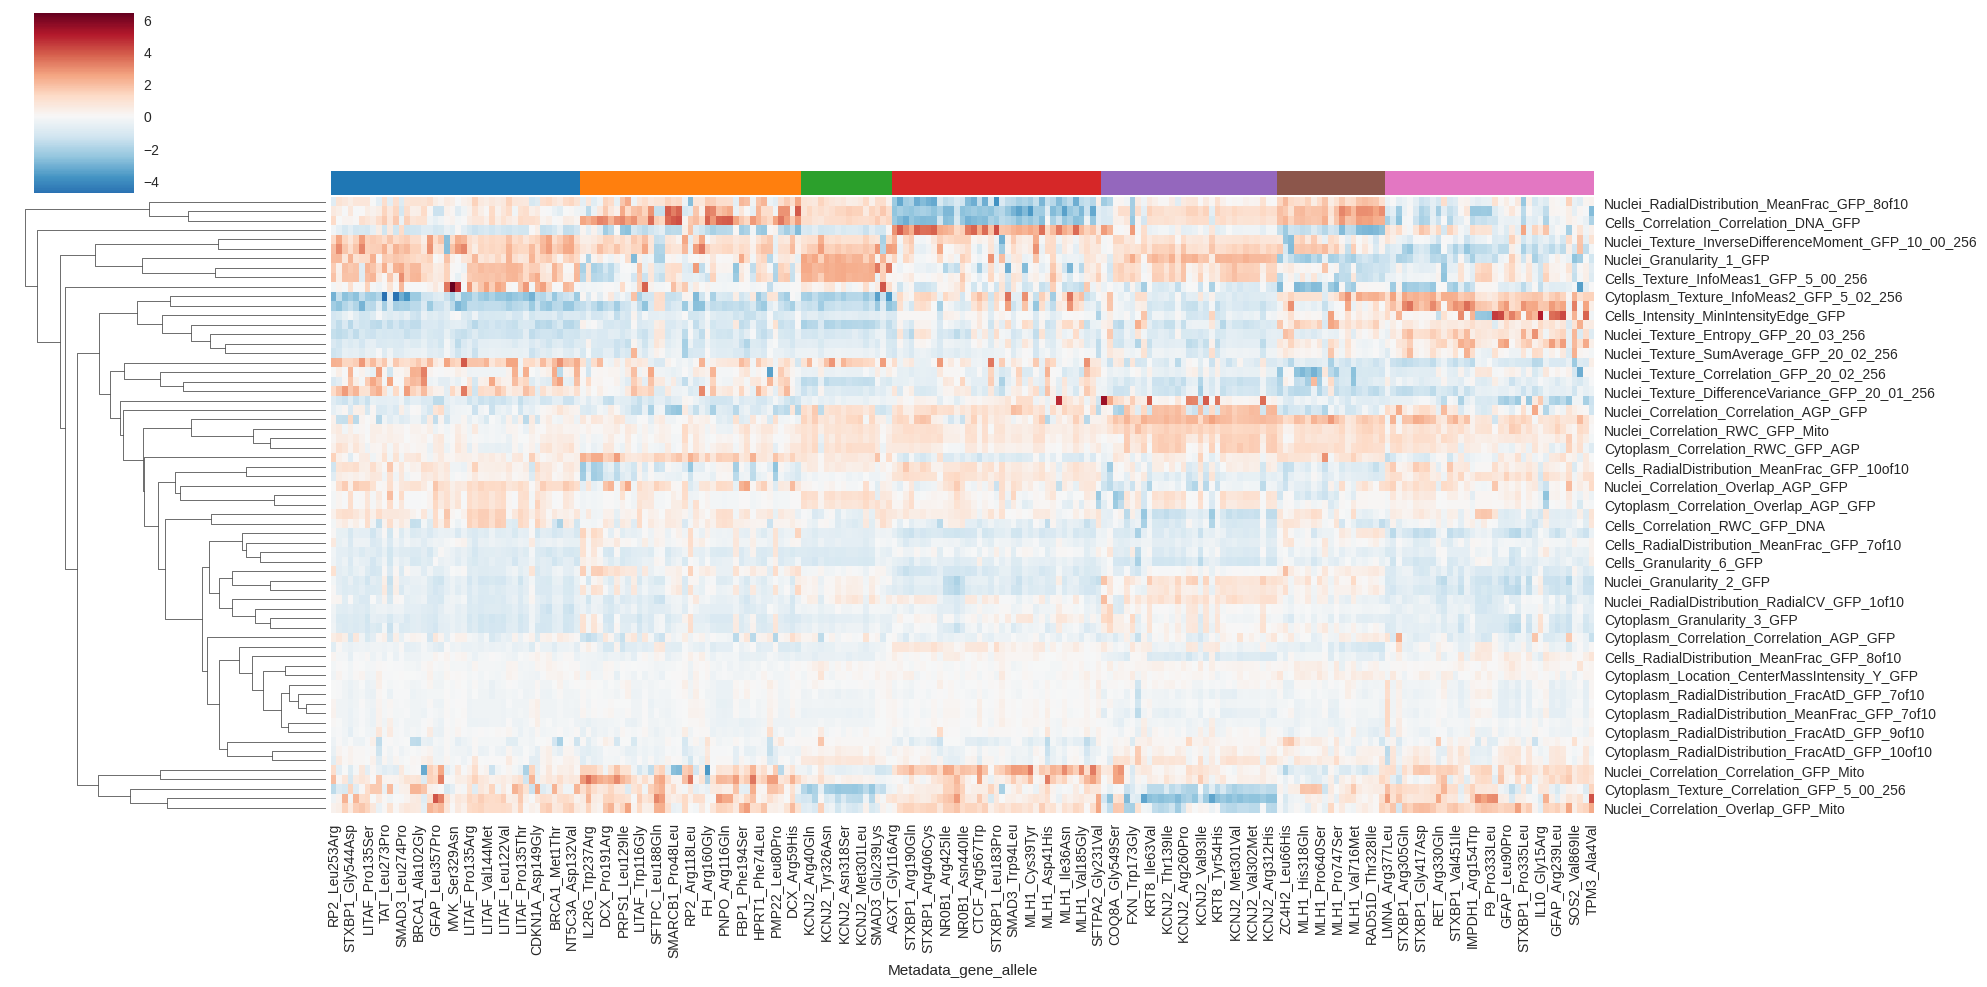

In [128]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Create dataframe with cluster labels
# df_clustered = pd.DataFrame(data_pca, columns=[f'PC{i+1}' for i in range(data_pca.shape[1])])
df_clustered = norm_vars_hits_feat_sel_df.set_index("Metadata_gene_allele").fillna(0).copy()
df_clustered['cluster'] = [clusters[i] for i in range(len(df_clustered))]

# Sort by cluster for better visualization
df_sorted = df_clustered.sort_values('cluster')
cluster_labels = df_sorted['cluster'].values
# Create cluster colormap
cluster_colors = sns.color_palette("tab10", len(set(cluster_labels)))

data_for_heatmap = df_sorted.drop('cluster', axis=1)
row_colors = [cluster_colors[c] for c in cluster_labels]

sns.clustermap(data_for_heatmap.T, 
               z_score=1,
               row_cluster=True, col_cluster=False,
               col_colors=row_colors,
               cmap='RdBu_r', center=0,
               figsize=(20, 10))
plt.show()

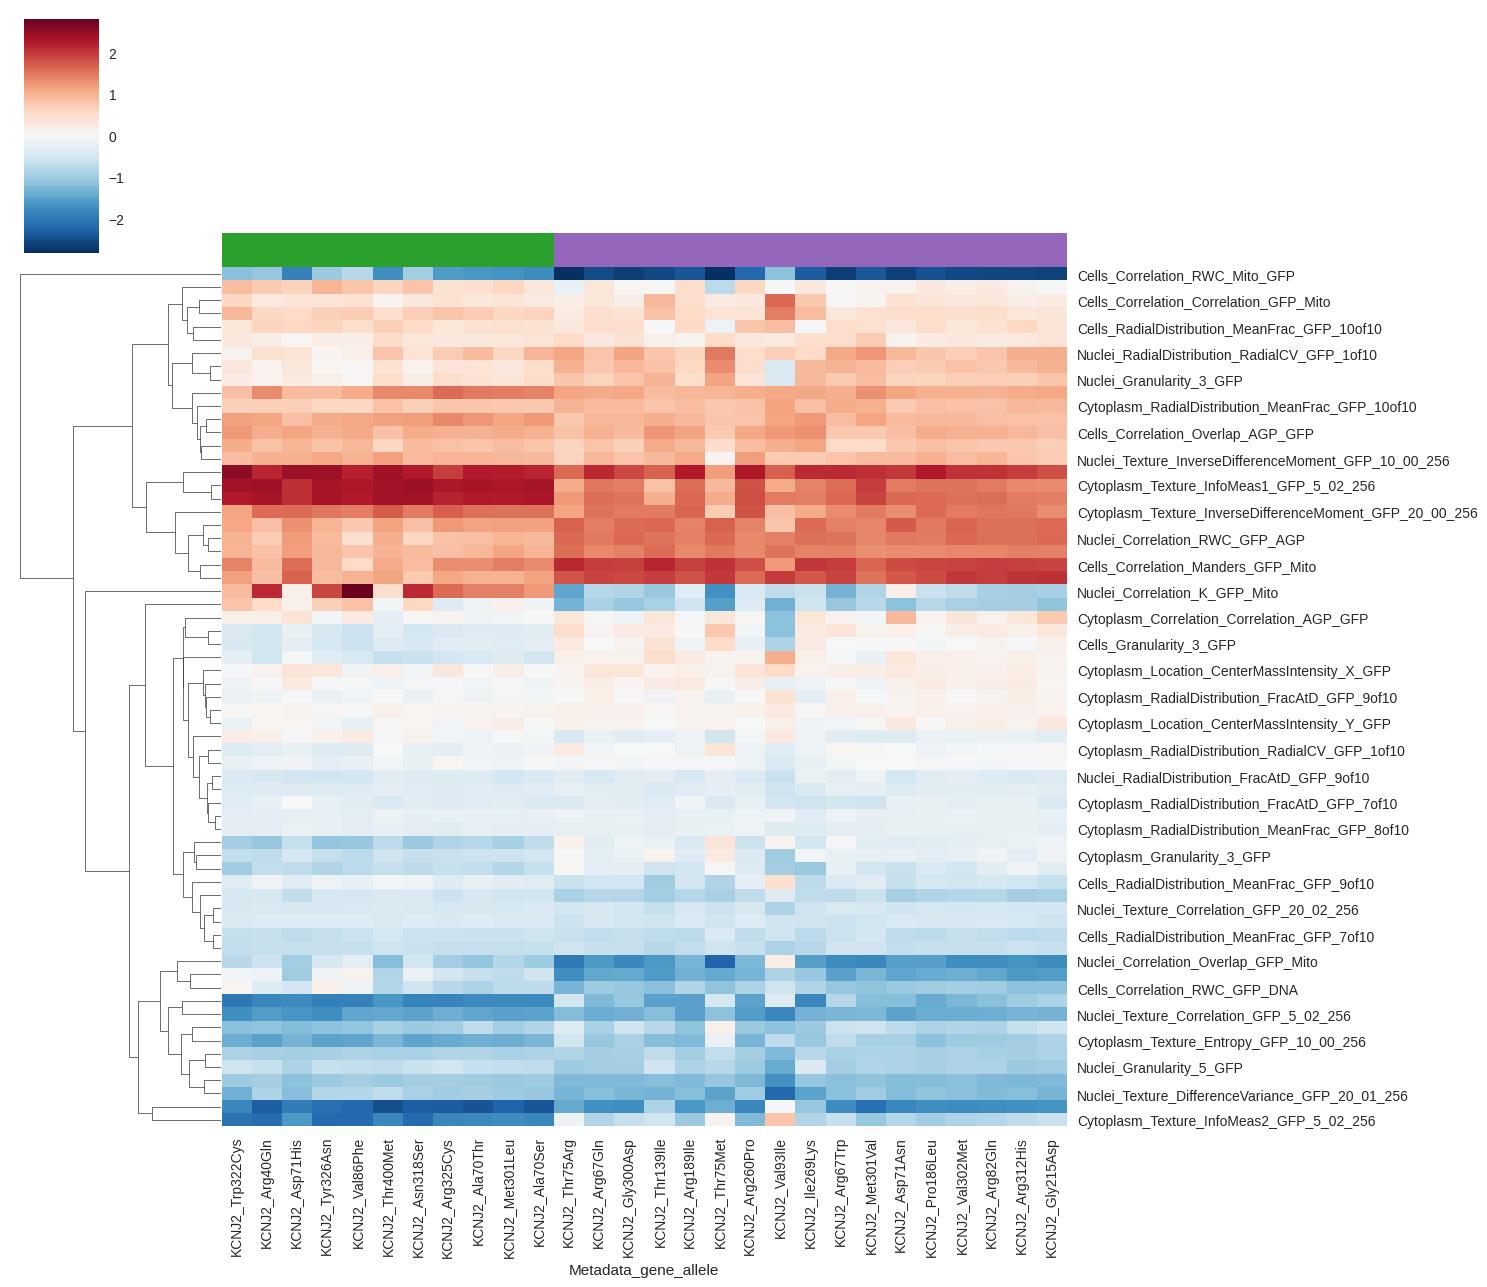

In [127]:
cluster_labels = df_sorted.loc[[var for var in data_for_heatmap.index if "KCNJ2" in var],:]['cluster'].values
data_for_heatmap = df_sorted.loc[[var for var in data_for_heatmap.index if "KCNJ2" in var],:].drop('cluster', axis=1)
row_colors_ = [cluster_colors[c] for c in cluster_labels]

sns.clustermap(data_for_heatmap.T, 
               z_score=1,
               row_cluster=True, 
               col_cluster=False,
               col_colors=row_colors_,
               cmap='RdBu_r', center=0,
               figsize=(15, 13))
plt.show()

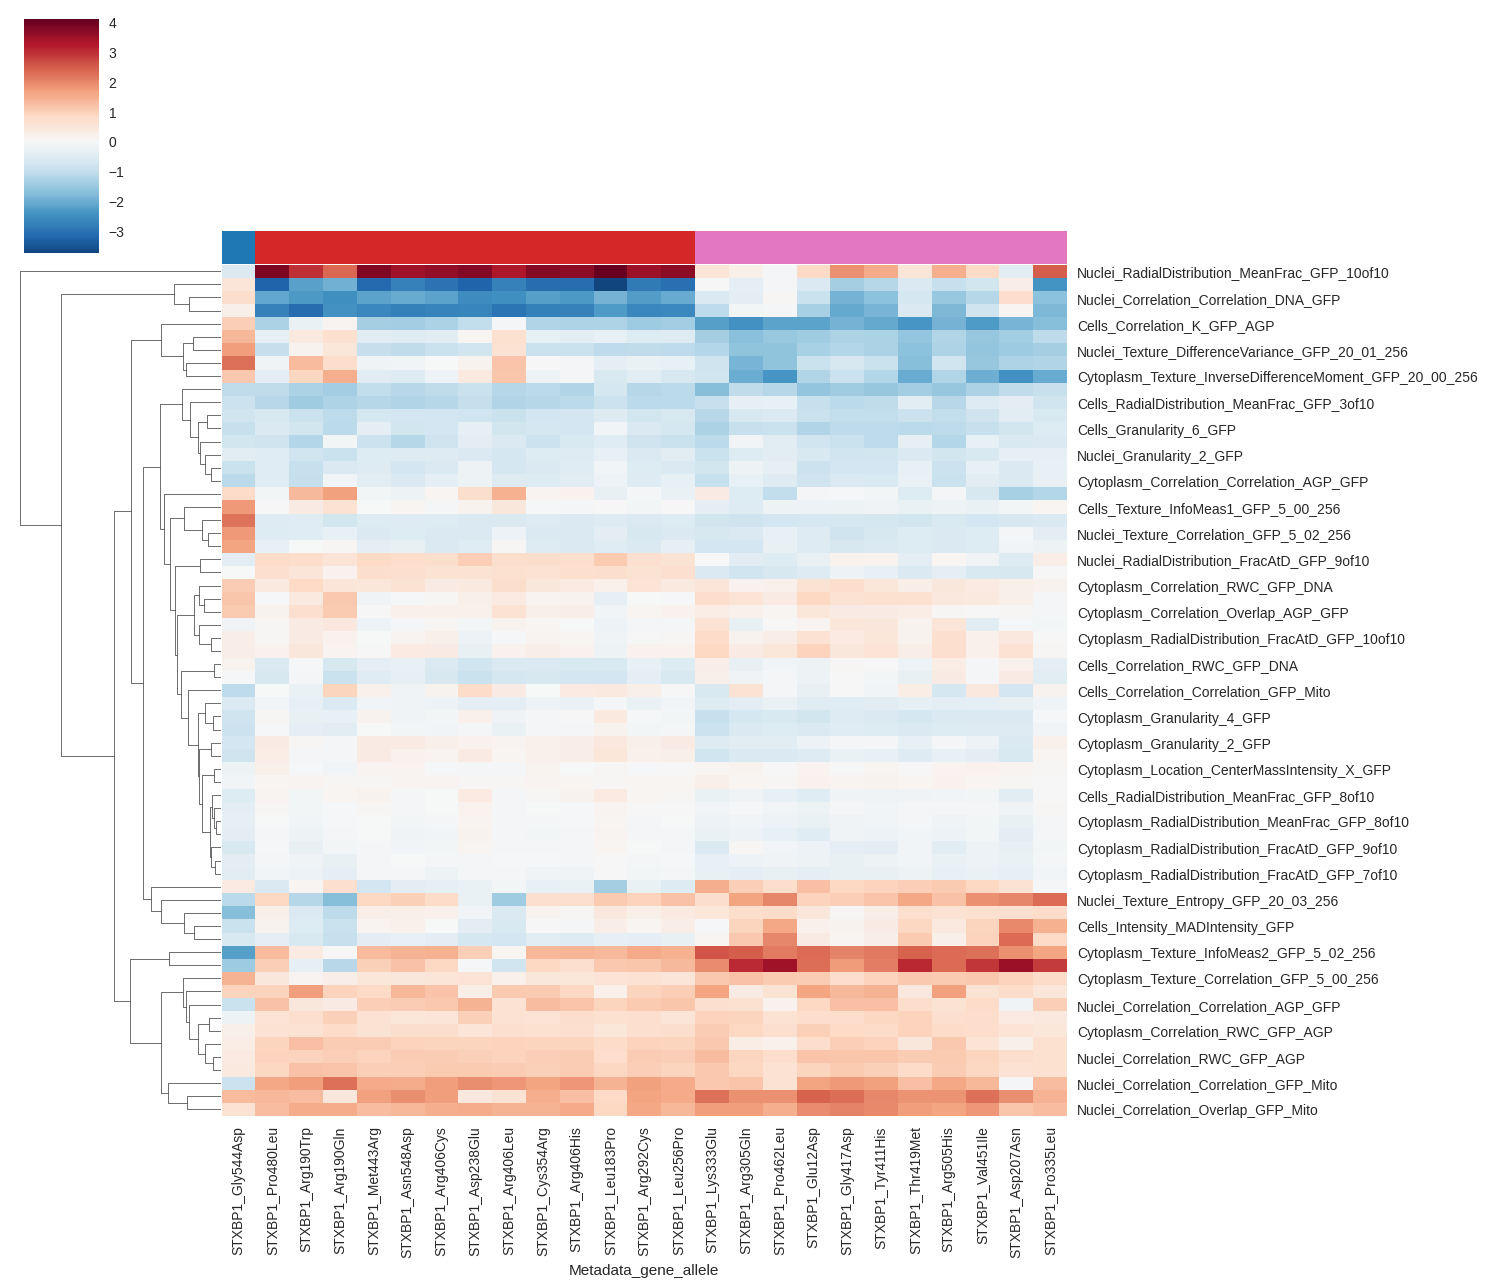

In [129]:
cluster_labels = df_sorted.loc[[var for var in data_for_heatmap.index if "STXBP1" in var],:]['cluster'].values
data_for_heatmap = df_sorted.loc[[var for var in data_for_heatmap.index if "STXBP1" in var],:].drop('cluster', axis=1)
row_colors_ = [cluster_colors[c] for c in cluster_labels]

sns.clustermap(data_for_heatmap.T, 
               z_score=1,
               row_cluster=True, col_cluster=False,
               col_colors=row_colors_,
               cmap='RdBu_r', center=0,
               figsize=(15, 13))
plt.show()

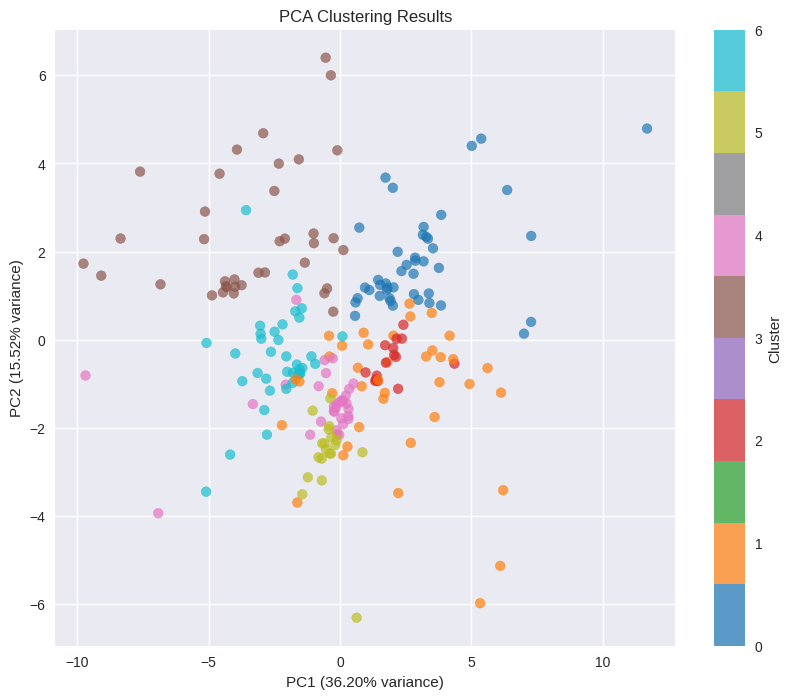

In [130]:
plt.figure(figsize=(10, 8))
scatter = plt.scatter(data_pca[:, 0], data_pca[:, 1], 
                     c=[clusters[i] for i in range(len(data_pca))],
                     cmap='tab10', s=50, alpha=0.7)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
plt.colorbar(scatter, label='Cluster')
plt.title('PCA Clustering Results')
plt.show()

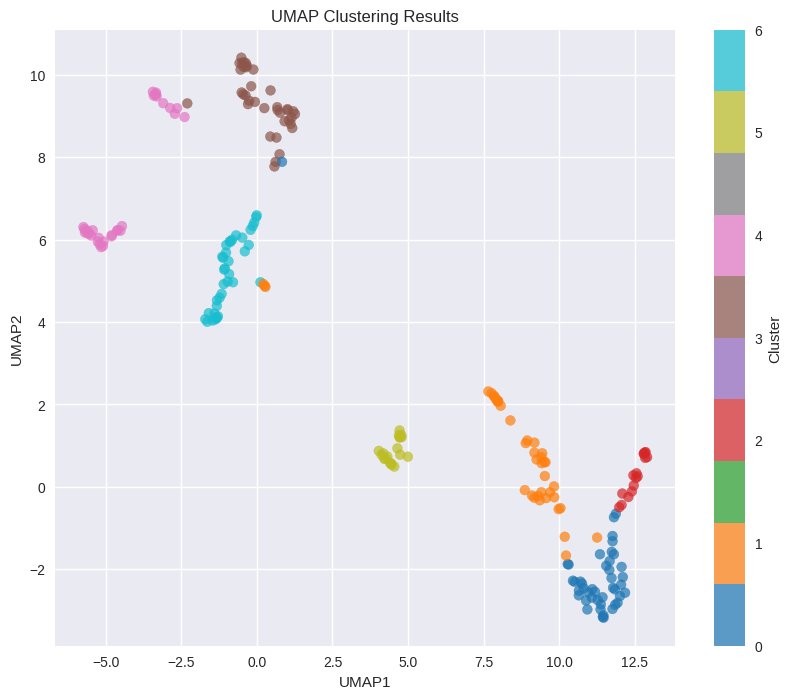

In [131]:
import umap

reducer = umap.UMAP(n_components=2, metric='cosine', random_state=42)
embedding = reducer.fit_transform(data_pca)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(embedding[:, 0], embedding[:, 1],
                     c=[clusters[i] for i in range(len(data_pca))],
                     cmap='tab10', s=50, alpha=0.7)
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')
plt.colorbar(scatter, label='Cluster')
plt.title('UMAP Clustering Results')
plt.show()

In [137]:
df_clustered

,Cells_Correlation_RWC_Mito_GFP,Cells_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_K_GFP_Mito,Nuclei_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Nuclei_Correlation_RWC_GFP_AGP,Nuclei_Correlation_Overlap_AGP_GFP,Nuclei_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_GFP_Mito,...,Cytoplasm_Correlation_Correlation_AGP_GFP,Cells_Correlation_K_GFP_AGP,Nuclei_Granularity_5_GFP,Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cells_Granularity_3_GFP,Cells_Intensity_MinIntensityEdge_GFP,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_00_256,cluster
Metadata_gene_allele,,,,,,,,,,,,,,,,,,,,,
RP2_Leu253Arg,-0.064547,-0.937824,2.050605,-0.014207,0.643868,0.405943,0.239993,0.104302,1.088756,1.811196,...,0.541386,0.000000,0.181474,1.160329,0.099514,-1.731587,-0.117954,-0.850797,1.768970,0
RP2_Cys86Tyr,0.061934,-0.856840,1.175555,0.154386,0.418535,0.498122,0.340047,0.129297,1.266272,1.918618,...,0.392023,0.000000,0.180130,1.178114,-0.104941,-1.750169,-0.041980,-0.852398,1.783414,0
RP2_Arg118Leu,0.612654,-1.934060,-0.077682,2.052358,-0.386360,0.006068,0.296699,-0.526355,2.079219,3.461106,...,0.026868,0.000000,1.473959,-0.243251,0.066546,-0.191208,1.367877,-0.797248,-0.076904,1
SMARCB1_Arg37His,0.660789,-0.352902,-0.356684,-1.847015,4.136565,0.447463,-0.120797,0.085910,-3.115320,0.232852,...,-0.110350,1.000281,0.358677,0.228276,0.046059,-0.876126,-0.310812,-0.472101,0.948773,1
SMARCB1_Pro48Leu,0.484833,-0.182849,0.082400,-1.619475,3.516246,0.615979,-0.077730,0.264095,-2.700193,0.344343,...,-0.267575,2.119349,0.092174,0.724421,0.044321,-0.878464,-0.395016,-0.520093,0.972017,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
STXBP1_Arg305Gln,0.339387,0.094406,-0.729435,0.061880,-0.213761,0.041429,0.334900,0.372179,0.441908,0.201887,...,-0.170639,-1.040681,-0.466231,-0.257524,-0.197303,1.202274,-0.286511,0.000000,-0.867726,6
STXBP1_Arg406His,0.306380,0.397719,-0.273672,1.824638,-1.252191,0.144315,0.483516,-0.198490,0.881091,0.145146,...,-0.289128,-0.691072,-0.675895,0.051686,-0.151245,0.305175,-0.085285,0.000000,-0.105175,3
LMNA_Arg377Leu,2.594342,1.006751,-0.137233,1.134906,-0.828978,-0.255449,0.495380,1.281045,1.056849,0.938133,...,0.962803,0.000000,-0.620214,0.939069,1.197455,1.229831,-0.763827,1.253626,-0.996663,6


In [135]:
map_clus_df = pl.DataFrame(df_clustered.reset_index()).join(
    imaging_summary_clinvar_hits,
    left_on="Metadata_gene_allele",
    right_on="gene_allele"
)

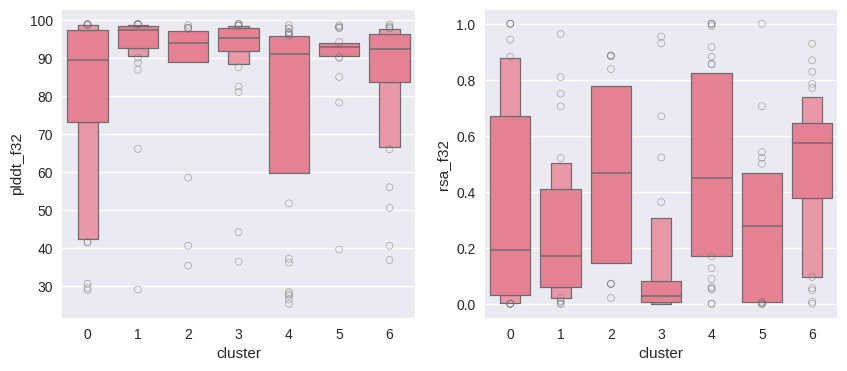

In [140]:
fig, ax = plt.subplots(1,2,figsize=(10,4))
sns.boxenplot(
    data=map_clus_df.to_pandas(),
    x="cluster",
    y="plddt_f32",
    ax=ax[0]
)
sns.boxenplot(
    data=map_clus_df.to_pandas(),
    x="cluster",
    y="rsa_f32",
    ax=ax[1]
)
plt.show()

In [162]:
from scipy.stats import ks_2samp
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np

def analyze_cluster_features(data_original, clusters, feature_names=None, 
                           significance_threshold=0.001, top_n=0, 
                           sort_by='effect_size'):
    """
    Identify differential features for each cluster using KS-test
    
    Parameters:
    -----------
    data_original: samples x features (rows=samples, columns=features)
    clusters: dict {sample_index: cluster_id}
    significance_threshold: p-value threshold after Bonferroni correction
    top_n: int, number of top features to return. If 0, return all significant features
    sort_by: str, sorting method {'effect_size', 'p_value', 'combined'}
        - 'effect_size': sort by absolute effect size (largest first)
        - 'p_value': sort by corrected p-value (smallest first)  
        - 'combined': sort by significance first, then effect size
    """
    # Convert to numpy array if DataFrame
    if isinstance(data_original, pd.DataFrame):
        data_array = data_original.values
        if feature_names is None:
            feature_names = data_original.columns.tolist()
    else:
        data_array = data_original
        if feature_names is None:
            feature_names = [f'Feature_{i}' for i in range(data_array.shape[1])]
    
    results = {}
    
    for cluster_id in set(clusters.values()):
        # Get sample indices for this cluster vs others
        cluster_sample_indices = [i for i, c in clusters.items() if c == cluster_id]
        other_sample_indices = [i for i, c in clusters.items() if c != cluster_id]
        
        # Extract data for samples in this cluster vs others
        cluster_data = data_array[cluster_sample_indices, :]
        other_data = data_array[other_sample_indices, :]
        
        # Perform KS-test for each feature
        p_values = []
        statistics = []
        
        for feature_idx in range(data_array.shape[1]):
            cluster_feature_values = cluster_data[:, feature_idx]
            other_feature_values = other_data[:, feature_idx]
            
            stat, p_val = ks_2samp(cluster_feature_values, other_feature_values)
            p_values.append(p_val)
            statistics.append(stat)
        
        # Bonferroni correction
        rejected, p_corrected, _, _ = multipletests(p_values, method='bonferroni')
        
        # Calculate effect size (difference in medians)
        effect_sizes = []
        for feature_idx in range(data_array.shape[1]):
            cluster_median = np.median(cluster_data[:, feature_idx])
            other_median = np.median(other_data[:, feature_idx])
            effect_sizes.append(cluster_median - other_median)
        
        # Create results dataframe for this cluster
        cluster_results = pd.DataFrame({
            'feature': feature_names,
            'ks_statistic': statistics,
            'p_value': p_values,
            'p_corrected': p_corrected,
            'significant': rejected,
            'effect_size': effect_sizes,
            'abs_effect_size': np.abs(effect_sizes)
        })
        
        # Apply filtering and sorting based on parameters
        if top_n == 0:
            # Return all significant features
            filtered_results = cluster_results[cluster_results['p_corrected'] < significance_threshold]
        else:
            # Return top_n features regardless of significance
            filtered_results = cluster_results.copy()
        
        # Sort based on chosen method
        if sort_by == 'effect_size':
            filtered_results = filtered_results.sort_values('abs_effect_size', ascending=False)
        elif sort_by == 'p_value':
            filtered_results = filtered_results.sort_values('p_corrected', ascending=True)
        elif sort_by == 'combined':
            filtered_results = filtered_results.sort_values(
                ['significant', 'abs_effect_size'], 
                ascending=[False, False]
            )
        
        # Apply top_n limit if specified
        if top_n > 0:
            filtered_results = filtered_results.head(top_n)
        
        results[f'Cluster_{cluster_id}'] = filtered_results
    
    return results


def display_results(cluster_results, clusters):
    """Display results in formatted way"""
    for cluster_name, df in cluster_results.items():
        cluster_id = int(cluster_name.split('_')[1])
        n_samples = sum(1 for c in clusters.values() if c == cluster_id)
        n_features = len(df)
        n_significant = (df['p_corrected'] < 0.001).sum()
        
        print(f"\n{cluster_name} (n={n_samples}):")
        print(f"Features shown: {n_features} (significant: {n_significant})")
        
        if n_features > 0:
            for idx, row in df.iterrows():
                sig_marker = "***" if row['p_corrected'] < 0.001 else "**" if row['p_corrected'] < 0.01 else "*" if row['p_corrected'] < 0.05 else ""
                direction = "↑" if row['effect_size'] > 0 else "↓"
                print(f"  {row['feature']}: KS={row['ks_statistic']:.3f}, p_corr={row['p_corrected']:.2e} {sig_marker}, effect={row['effect_size']:.3f} {direction}")
        else:
            print("  No features found")

# Usage examples:

# 1. All significant features (p < 0.001), sorted by effect size
results_all_sig = analyze_cluster_features(data_scaled, clusters, 
                                           significance_threshold=0.001, 
                                           top_n=0, 
                                           sort_by='combined')
print("=== ALL SIGNIFICANT FEATURES (p < 0.001) ===")
display_results(results_all_sig, clusters)

# 2. Top 3 features regardless of significance, sorted by p-value
results_top3_pval = analyze_cluster_features(data_scaled, clusters, 
                                            top_n=3, 
                                            sort_by='p_value')
print("\n\n=== TOP 3 FEATURES BY P-VALUE ===")
display_results(results_top3_pval, clusters)

# 3. Top 5 features, sorted by combined significance + effect size
results_top5_combined = analyze_cluster_features(data_scaled, clusters, 
                                                top_n=5, 
                                                sort_by='combined')
print("\n\n=== TOP 5 FEATURES BY COMBINED RANKING ===")
display_results(results_top5_combined, clusters)

# 4. All significant features with stricter threshold (p < 0.0001)
results_strict = analyze_cluster_features(data_scaled, clusters, 
                                        significance_threshold=0.0001, 
                                        top_n=0, 
                                        sort_by='p_value')
print("\n\n=== ALL SIGNIFICANT FEATURES (p < 0.0001) ===")
display_results(results_strict, clusters)


Cluster_0 (n=44):
Significant features (p < 0.001): 30
  Cytoplasm_Texture_InfoMeas2_GFP_5_02_256: KS=0.703, p_corr=7.92e-16, effect=-1.457 ↓
  Nuclei_Correlation_K_GFP_Mito: KS=0.709, p_corr=3.88e-16, effect=1.298 ↑
  Nuclei_Texture_DifferenceVariance_GFP_20_01_256: KS=0.668, p_corr=6.93e-14, effect=1.138 ↑
  Cytoplasm_Texture_InfoMeas1_GFP_5_02_256: KS=0.497, p_corr=1.06e-06, effect=1.024 ↑
  Cells_Texture_InfoMeas1_GFP_5_00_256: KS=0.485, p_corr=2.57e-06, effect=1.004 ↑
  Cytoplasm_Texture_Entropy_GFP_10_00_256: KS=0.680, p_corr=1.64e-14, effect=-0.858 ↓
  Nuclei_Granularity_1_GFP: KS=0.557, p_corr=6.39e-09, effect=0.783 ↑
  Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256: KS=0.658, p_corr=2.19e-13, effect=0.712 ↑
  Cells_RadialDistribution_RadialCV_GFP_10of10: KS=0.635, p_corr=2.89e-12, effect=-0.665 ↓
  Cells_Correlation_Manders_GFP_Mito: KS=0.584, p_corr=5.16e-10, effect=-0.607 ↓
  Nuclei_Correlation_Overlap_AGP_GFP: KS=0.550, p_corr=1.30e-08, effect=0.580 ↑
  Cytoplasm_Tex

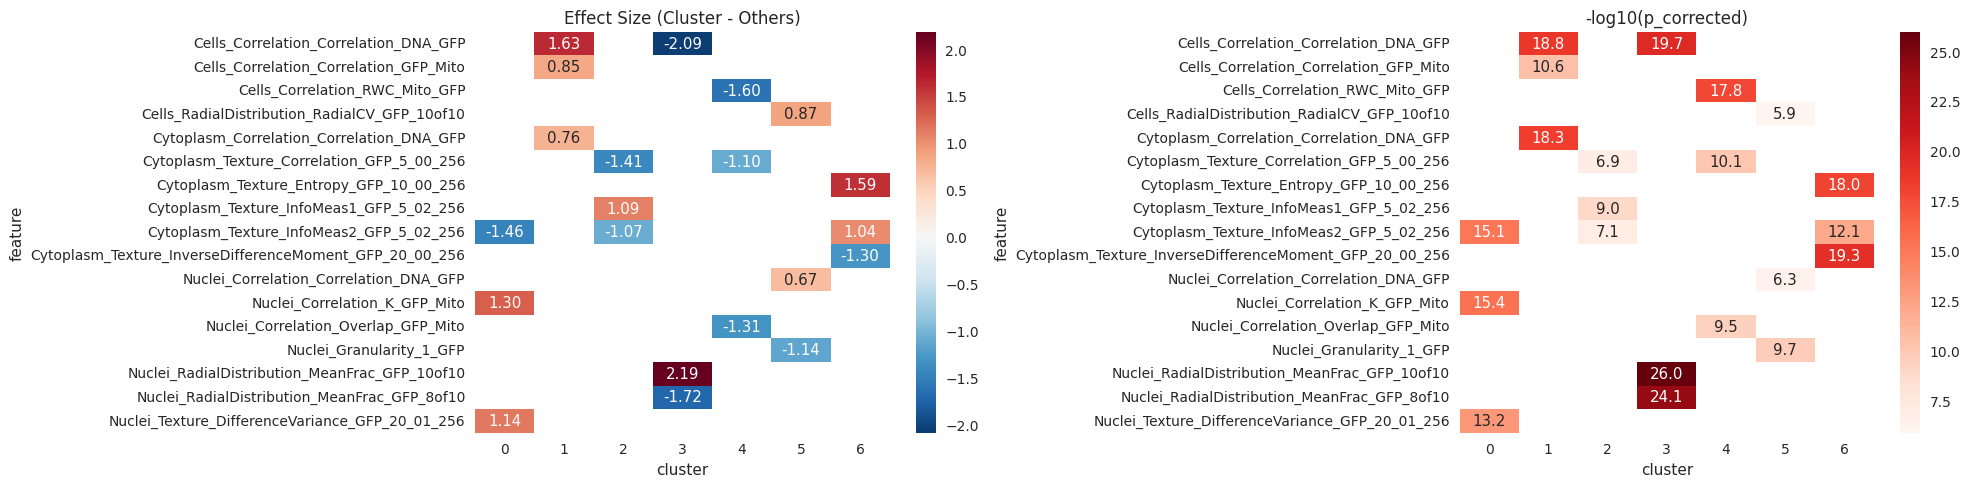

In [161]:
def plot_top_features_heatmap(cluster_results, top_n=3):
    """Plot heatmap of top differential features per cluster"""
    top_features_data = []
    
    for cluster_name, df in cluster_results.items():
        cluster_id = cluster_name.split('_')[1]
        top_features = df.head(top_n)
        
        for _, row in top_features.iterrows():
            top_features_data.append({
                'cluster': cluster_id,
                'feature': row['feature'],
                'effect_size': row['effect_size'],
                'neg_log_p': -np.log10(row['p_corrected'] + 1e-300)
            })
    
    heatmap_df = pd.DataFrame(top_features_data)
    pivot_effect = heatmap_df.pivot(index='feature', columns='cluster', values='effect_size')
    pivot_significance = heatmap_df.pivot(index='feature', columns='cluster', values='neg_log_p')
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 5))
    
    sns.heatmap(pivot_effect, annot=True, cmap='RdBu_r', center=0, ax=ax1, fmt='.2f')
    ax1.set_title('Effect Size (Cluster - Others)')
    
    sns.heatmap(pivot_significance, annot=True, cmap='Reds', ax=ax2, fmt='.1f')
    ax2.set_title('-log10(p_corrected)')

    plt.tight_layout()
    plt.subplots_adjust(wspace=.9)
    plt.show()

sns.set_style(style='white')
plot_top_features_heatmap(cluster_results)

### 1.4 Aggregate the feature to batch-allele level

In [19]:
# ref_var_cell_all_prof_df = ref_var_cell_all_prof_df.with_columns(
#     pl.col("Metadata_Plate")
#       # capture a “B” followed by any non-underscore chars up to the first “A”
#       .str.extract(r"(B[^_]*?A)", 1)
#       .alias("Metadata_Batch")
# ).with_columns(
#     pl.col("Metadata_Batch").replace(BIO_BATCH_MAP_DICT).alias("Metadata_Bio_Batch")
# )

# ref_var_allele_batch_all_prof_df = ref_var_cell_all_prof_df.group_by(
#     "Metadata_Plate", "Metadata_Well", "Metadata_gene_allele", "Metadata_Bio_Batch"
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).group_by(
#     "Metadata_gene_allele", "Metadata_Bio_Batch"
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).unique(subset=["Metadata_gene_allele","Metadata_Bio_Batch"])

# non_null_cols_batch = [c for c in feat_df["cp_feature"].to_list() if c in ref_var_allele_batch_all_prof_df.columns]
# var_allele_meta_cols = [col for col in ref_var_allele_batch_all_prof_df.columns if "Metadata" in col]
# ref_var_allele_batch_all_prof_df = ref_var_allele_batch_all_prof_df.select(
#     var_allele_meta_cols+non_null_cols_batch
# )
# ref_var_allele_batch_all_prof_df

Metadata_gene_allele,Metadata_Bio_Batch,Cells_Correlation_RWC_Mito_GFP,Nuclei_Correlation_K_GFP_AGP,Cytoplasm_Intensity_MaxIntensity_GFP,Cells_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_K_GFP_Mito,Nuclei_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_RWC_GFP_DNA,Nuclei_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_Correlation_RWC_DNA_GFP,Nuclei_Texture_SumAverage_GFP_20_00_256,Cytoplasm_Granularity_1_GFP,Nuclei_Correlation_RWC_GFP_AGP,Cells_Correlation_RWC_DNA_GFP,Nuclei_Correlation_RWC_AGP_GFP,Cells_RadialDistribution_FracAtD_GFP_7of10,Nuclei_Correlation_Overlap_AGP_GFP,Nuclei_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_DNA_GFP,Cells_Texture_DifferenceVariance_GFP_20_01_256,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_Texture_Correlation_GFP_20_00_256,Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,Cells_Texture_InverseDifferenceMoment_GFP_20_03_256,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Cytoplasm_Granularity_4_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cells_Correlation_RWC_GFP_Mito,Cytoplasm_Granularity_2_GFP,Nuclei_RadialDistribution_FracAtD_GFP_5of10,Cells_Correlation_Manders_GFP_Mito,Cells_RadialDistribution_MeanFrac_GFP_7of10,Cells_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Correlation_RWC_GFP_AGP,…,Cytoplasm_Texture_Correlation_GFP_5_01_256,Cytoplasm_Texture_InfoMeas1_GFP_20_03_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_01_256,Cells_Texture_AngularSecondMoment_GFP_20_02_256,Cytoplasm_Correlation_Correlation_AGP_GFP,Cells_Texture_InverseDifferenceMoment_GFP_5_00_256,Nuclei_RadialDistribution_FracAtD_GFP_3of10,Nuclei_Texture_AngularSecondMoment_GFP_10_00_256,Cells_Correlation_RWC_GFP_AGP,Nuclei_Texture_SumAverage_GFP_20_01_256,Cytoplasm_RadialDistribution_MeanFrac_GFP_4of10,Cytoplasm_Texture_AngularSecondMoment_GFP_5_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_10_01_256,Nuclei_RadialDistribution_FracAtD_GFP_4of10,Cytoplasm_RadialDistribution_RadialCV_GFP_4of10,Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256,Cytoplasm_Texture_InfoMeas2_GFP_10_03_256,Nuclei_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_InverseDifferenceMoment_GFP_10_01_256,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cytoplasm_Texture_InfoMeas1_GFP_20_00_256,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cells_Texture_InfoMeas1_GFP_10_01_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cells_Granularity_3_GFP,Cells_Texture_Entropy_GFP_5_00_256,Cells_Texture_InfoMeas2_GFP_5_02_256,Nuclei_Texture_Correlation_GFP_10_03_256,Cytoplasm_RadialDistribution_FracAtD_GFP_6of10,Nuclei_RadialDistribution_MeanFrac_GFP_7of10,Cytoplasm_Texture_Entropy_GFP_20_03_256,Nuclei_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_20_01_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_00_256
str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""THAP1_Val193Ile""","""B7A""",-0.471381,0.30363,-0.855684,-0.098502,1.281638,-1.503473,1.243952,2.200505,0.823849,0.744993,-0.068026,1.291592,-0.67536,1.270144,-0.572945,0.000919,-0.889777,-1.161589,-0.111733,2.982598,3.686163,-1.511673,4.215372,-0.995179,0.99559,0.015394,-0.460648,2.00149,-0.614915,-0.982061,1.422735,-0.569082,-0.075004,0.517468,0.162354,…,1.136268,1.0,1.569049,2.139963,-0.54894,0.986725,1.13695,1.022571,-0.038973,-0.065695,-0.18443,1.0,2.306587,1.212851,-0.860611,0.981051,-1.0,1.454203,1.0,0.017828,1.0,-1.0,0.995265,1.398547,1.0,0.991164,-0.1125,-0.981556,-1.494422,0.73372,0.042101,1.48114,-1.0,0.962871,3.046467,1.0,1.0
"""F9_Arg384Leu""","""B13A

In [20]:
# ref_var_allele_batch_all_prof_df.write_csv("../../3_outputs/all_batch_alleles_featselect_cp_features.csv")

### 1.5 Process the CP feature by INT and remove correlated features

In [21]:
ref_var_allele_batch_all_prof_df = pl.read_csv("../../3_outputs/all_batch_alleles_featselect_cp_features.csv")
ref_var_allele_batch_all_prof_df = ref_var_allele_batch_all_prof_df.filter(pl.col("Metadata_gene_allele").is_in(allele_list))

In [21]:
sns.displot(
    x=ref_var_allele_batch_all_prof_df.select(
        pl.col([c for c in ref_var_allele_batch_all_prof_df.columns if "Meta" not in c])
    ).mean().transpose(include_header=True).rename({"column_0": "CP_Feature_Mean"})["CP_Feature_Mean"],
    height=4, aspect=1.2
)

In [39]:
from utils import *
from pycytominer.feature_select import feature_select

## normalize the features
ref_var_allele_batch_proc_prof_df = inverse_normal_transform(ref_var_allele_batch_all_prof_df)

## remove corr features
ref_var_allele_batch_proc_prof_df = feature_select(ref_var_allele_batch_proc_prof_df.to_pandas(), operation="variance_threshold")
ref_var_allele_batch_proc_prof_df = feature_select(ref_var_allele_batch_proc_prof_df, operation="correlation_threshold")

# ref_var_allele_batch_proc_prof_df = remove_corr_feats(ref_var_allele_batch_proc_prof_df)

In [42]:
ref_var_allele_batch_proc_prof_df = pl.DataFrame(ref_var_allele_batch_proc_prof_df)

Computing UMAP embedding...


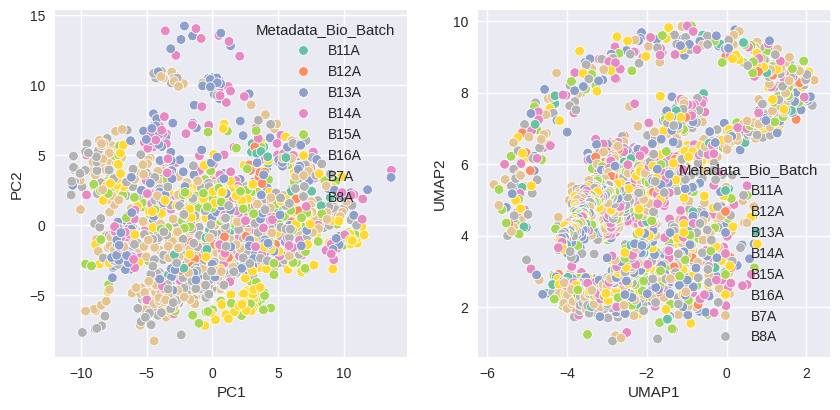

In [43]:
# UMAP - excellent for binary/sparse data
print("Computing UMAP embedding...")
umap_reducer = umap.UMAP(n_components=2, random_state=42, 
                       metric='jaccard', n_neighbors=15, min_dist=0.1)
X_umap = umap_reducer.fit_transform(ref_var_allele_batch_proc_prof_df.select(
    [c for c in ref_var_allele_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(ref_var_allele_batch_proc_prof_df.select(
    [c for c in ref_var_allele_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

umap_df = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_Bio_Batch"] = ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"]
umap_df["Metadata_gene_allele"] = ref_var_allele_batch_proc_prof_df["Metadata_gene_allele"]

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Metadata_Bio_Batch"] = ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"]
pca_df["Metadata_gene_allele"] = ref_var_allele_batch_proc_prof_df["Metadata_gene_allele"]

fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Metadata_Bio_Batch", palette="Set2", ax=axes[0],
                hue_order=sorted(ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"].unique()))
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="Metadata_Bio_Batch", palette="Set2",  ax=axes[1],
               hue_order=sorted(ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"].unique()))
plt.show()

### 1.6 Loading gene location info

In [50]:
gene_loc_df = pl.read_csv("../../3_outputs/agg_gene_normalized_cp_profiles_subloc.csv")
hits_gene_loc_df = gene_loc_df.filter(
    pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["Gene"].unique())
)
hits_gene_w_loc_df = hits_gene_loc_df.filter(
    ~pl.col("Final_Loc").is_in(["Unknown", "Uncertain"])
)
# hits_gene_w_loc_df

# fig, axes = plt.subplots(1,2,figsize=(15,5))
# sns.barplot(
#     data=hits_gene_loc_df.group_by("Main location").agg(pl.len()).sort("len", descending=True),
#     x="len",
#     y="Main location",
#     ax=axes[0]
# )
# sns.barplot(
#     data=hits_gene_loc_df.group_by("Final_Loc").agg(pl.len()).sort("len", descending=True),
#     x="len",
#     y="Final_Loc",
#     ax=axes[1]
# )
# axes[0].set_title(f"Main Location of {hits_gene_loc_df.shape[0]} genes with mislocalized variants")
# axes[1].set_title(f"Approved Location of {hits_gene_loc_df.shape[0]} genes with mislocalized variants")
# axes[0].grid(alpha=.3, axis='x')
# axes[1].grid(alpha=.3, axis='x')
# plt.subplots_adjust(wspace=1)

## 2. Gene-level Analyses

In [51]:
ref_var_allele_all_prof_df = ref_var_allele_batch_all_prof_df.group_by(
    "Metadata_gene_allele"
).agg(
    pl.col(col).median().alias(col)
    for col in ref_var_allele_batch_all_prof_df.columns
    if not col.startswith("Metadata_")
)
ref_var_allele_all_prof_df

Metadata_gene_allele,Cells_Correlation_RWC_Mito_GFP,Nuclei_Correlation_K_GFP_AGP,Cytoplasm_Intensity_MaxIntensity_GFP,Cells_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_K_GFP_Mito,Nuclei_RadialDistribution_MeanFrac_GFP_10of10,Nuclei_Correlation_RWC_GFP_DNA,Nuclei_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Cytoplasm_Correlation_RWC_DNA_GFP,Nuclei_Texture_SumAverage_GFP_20_00_256,Cytoplasm_Granularity_1_GFP,Nuclei_Correlation_RWC_GFP_AGP,Cells_Correlation_RWC_DNA_GFP,Nuclei_Correlation_RWC_AGP_GFP,Cells_RadialDistribution_FracAtD_GFP_7of10,Nuclei_Correlation_Overlap_AGP_GFP,Nuclei_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_GFP_Mito,Cells_Correlation_Correlation_DNA_GFP,Cells_Texture_DifferenceVariance_GFP_20_01_256,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_Texture_Correlation_GFP_20_00_256,Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,Cells_Texture_InverseDifferenceMoment_GFP_20_03_256,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Cytoplasm_Granularity_4_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cells_Correlation_RWC_GFP_Mito,Cytoplasm_Granularity_2_GFP,Nuclei_RadialDistribution_FracAtD_GFP_5of10,Cells_Correlation_Manders_GFP_Mito,Cells_RadialDistribution_MeanFrac_GFP_7of10,Cells_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Correlation_RWC_GFP_AGP,Cells_Granularity_5_GFP,…,Cytoplasm_Texture_Correlation_GFP_5_01_256,Cytoplasm_Texture_InfoMeas1_GFP_20_03_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_01_256,Cells_Texture_AngularSecondMoment_GFP_20_02_256,Cytoplasm_Correlation_Correlation_AGP_GFP,Cells_Texture_InverseDifferenceMoment_GFP_5_00_256,Nuclei_RadialDistribution_FracAtD_GFP_3of10,Nuclei_Texture_AngularSecondMoment_GFP_10_00_256,Cells_Correlation_RWC_GFP_AGP,Nuclei_Texture_SumAverage_GFP_20_01_256,Cytoplasm_RadialDistribution_MeanFrac_GFP_4of10,Cytoplasm_Texture_AngularSecondMoment_GFP_5_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_10_01_256,Nuclei_RadialDistribution_FracAtD_GFP_4of10,Cytoplasm_RadialDistribution_RadialCV_GFP_4of10,Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256,Cytoplasm_Texture_InfoMeas2_GFP_10_03_256,Nuclei_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_InverseDifferenceMoment_GFP_10_01_256,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cytoplasm_Texture_InfoMeas1_GFP_20_00_256,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cells_Texture_InfoMeas1_GFP_10_01_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cells_Granularity_3_GFP,Cells_Texture_Entropy_GFP_5_00_256,Cells_Texture_InfoMeas2_GFP_5_02_256,Nuclei_Texture_Correlation_GFP_10_03_256,Cytoplasm_RadialDistribution_FracAtD_GFP_6of10,Nuclei_RadialDistribution_MeanFrac_GFP_7of10,Cytoplasm_Texture_Entropy_GFP_20_03_256,Nuclei_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_20_01_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_00_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_00_256
str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""LITAF_Ser15Leu""",-0.477558,0.717486,-0.183254,0.627137,1.27533,0.144792,0.250722,-0.197814,-0.013327,-0.334325,-0.011334,0.901319,0.306316,-0.268432,0.199564,-0.213056,0.468716,0.393389,-0.049446,-0.126044,2.468951,-0.088292,-0.242348,-0.705219,0.861093,0.320834,-0.517515,-0.358713,-0.079782,0.553564,0.07252,0.534915,-0.458006,-0.420067,0.315711,-0.777827,…,-0.878565,0.603774,1.562237,1.817582,0.318672,0.729908,0.063423,1.333577,0.364815,-0.008085,-0.330331,0.929973,1.512045,0.093269,-0.166459,0.807224,-0.709377,-0.173684,0.784866,0.079006,0.633194,-0.662935,0.775476,1.525042,0.665642,0.675899,-0.257083,-0.676013,-1.102249,-0.057135,0.022518,-0.150922,-0.622

In [52]:
## normalize the features
ref_var_allele_int_prof_df = inverse_normal_transform(ref_var_allele_all_prof_df)

## remove corr features
ref_var_allele_int_prof_df = feature_select(ref_var_allele_int_prof_df.to_pandas(), operation="variance_threshold")
ref_var_allele_int_featselect_prof_df = feature_select(ref_var_allele_int_prof_df, operation="correlation_threshold")

In [55]:
ref_var_allele_proc_prof_df = pl.DataFrame(ref_var_allele_int_featselect_prof_df)

In [56]:
ref_var_allele_proc_prof_df = ref_var_allele_proc_prof_df.join(
    hits_gene_loc_df.select("Metadata_gene_allele","Main location"),
    on="Metadata_gene_allele",
    how="left"
).with_columns(
    pl.when(pl.col("Metadata_gene_allele").str.contains("_"))
    .then(pl.lit("VAR"))
    .otherwise(pl.lit("REF"))
    .alias("Metadata_allele_type"),
    pl.col("Main location").fill_null("Unknown")
).rename(
    {"Main location": "Metadata_main_loc"}
)

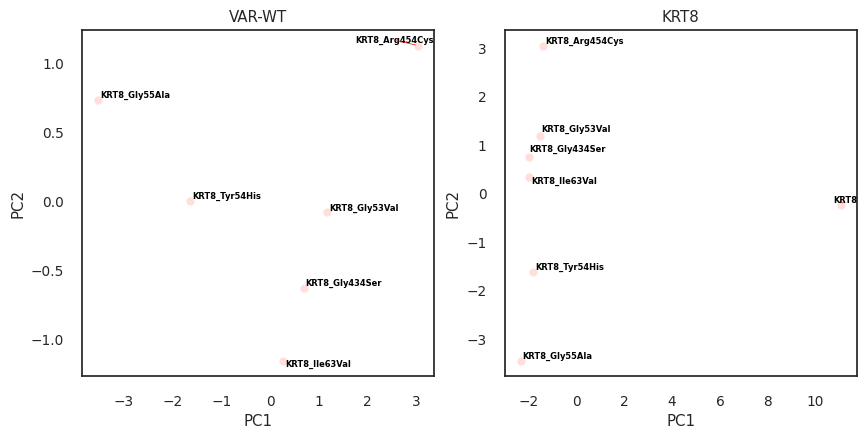

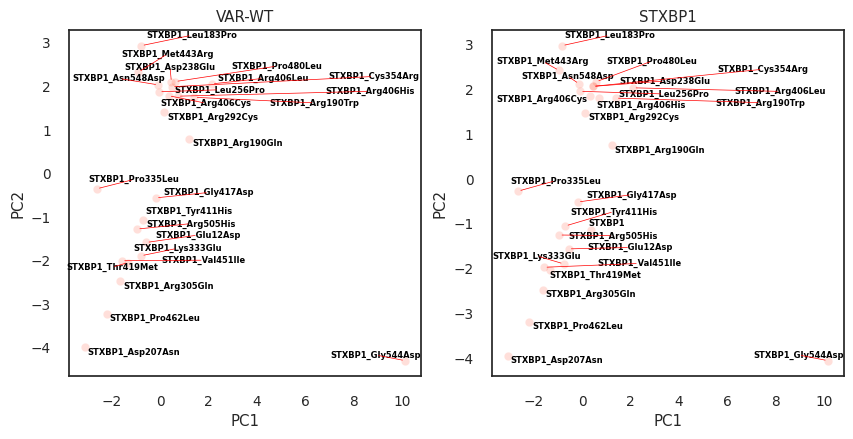

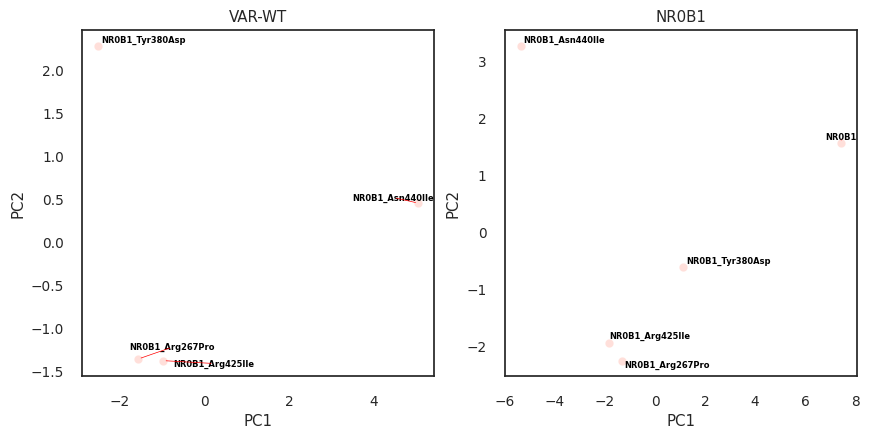

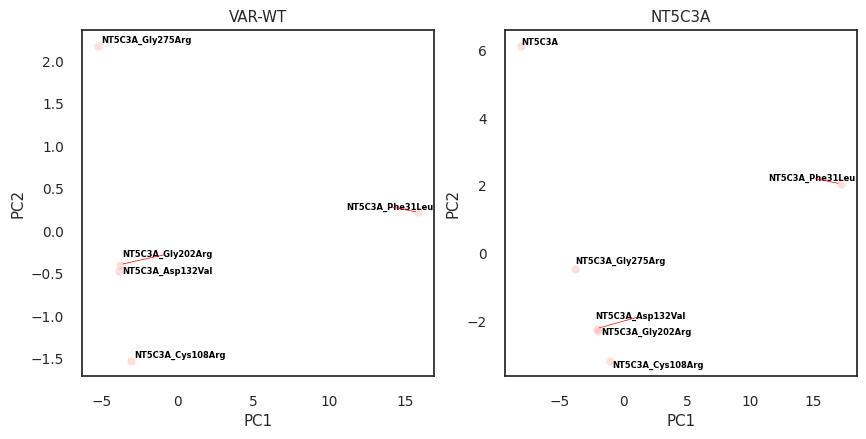

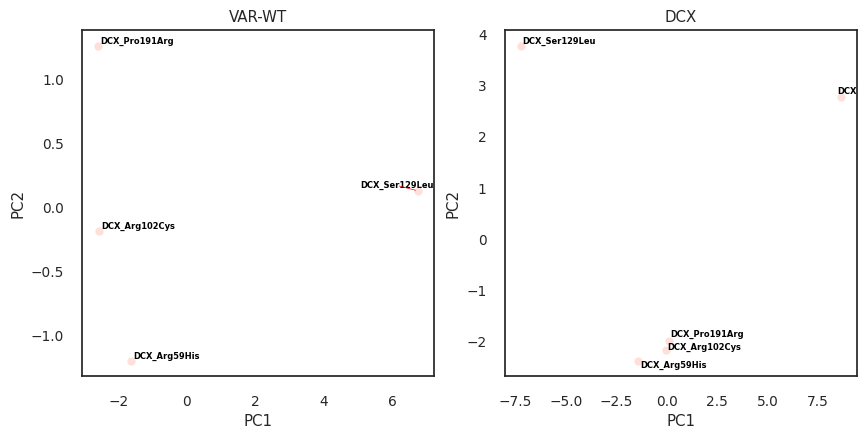

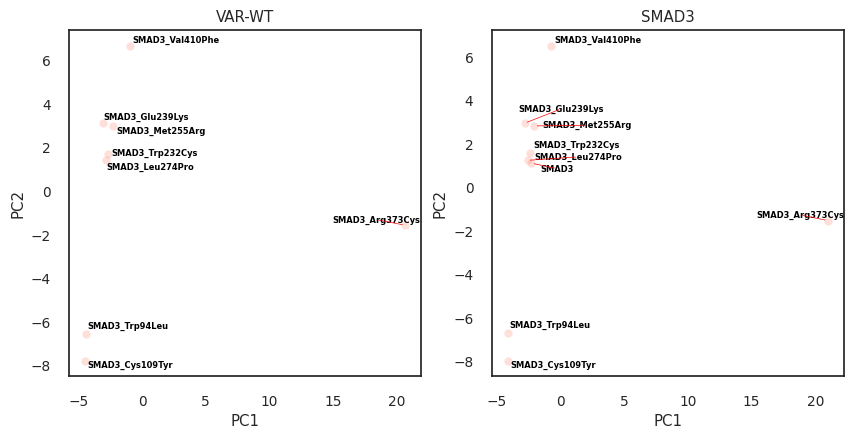

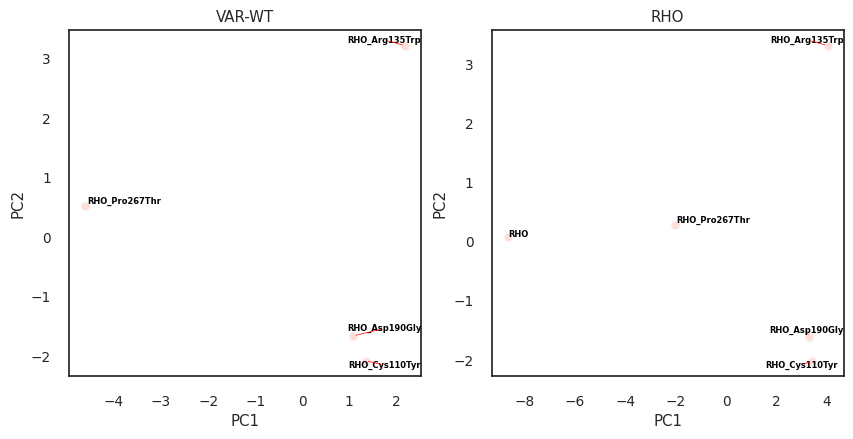

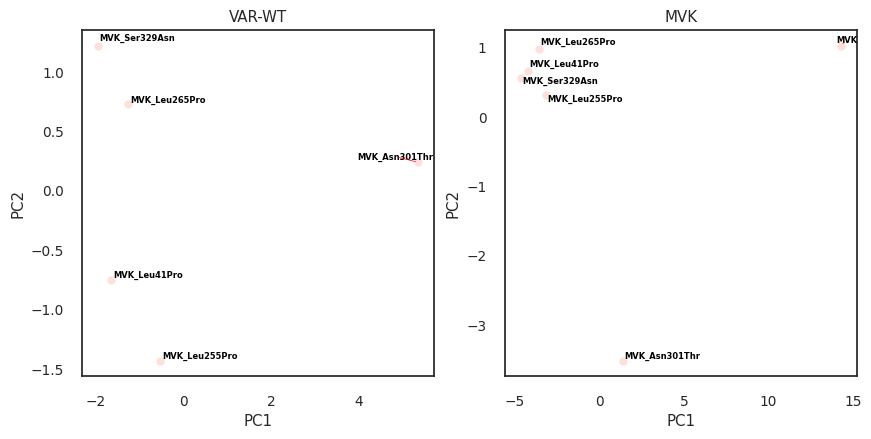

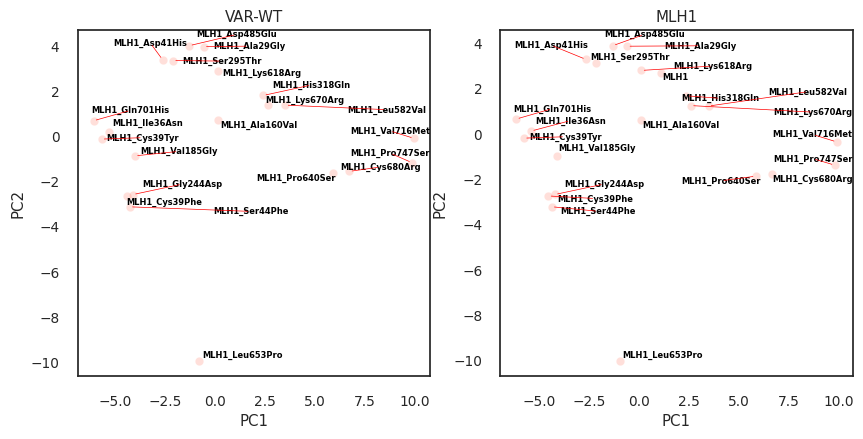

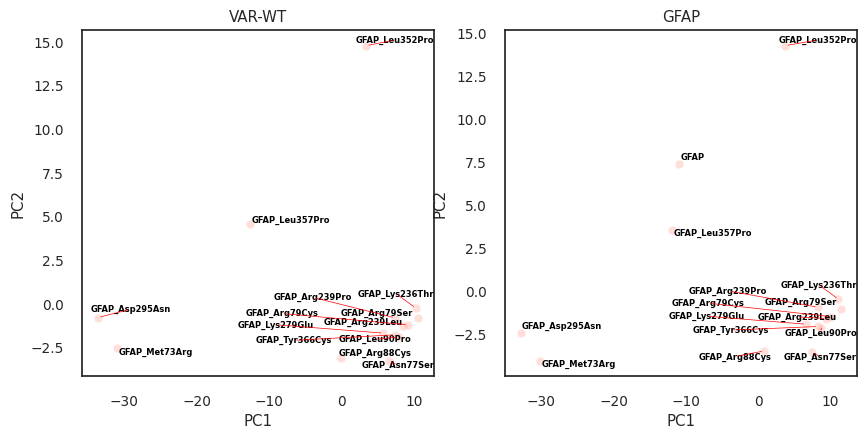

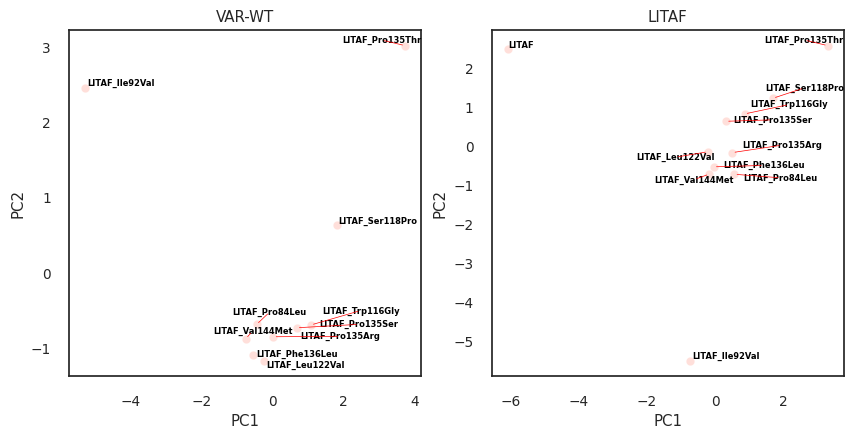

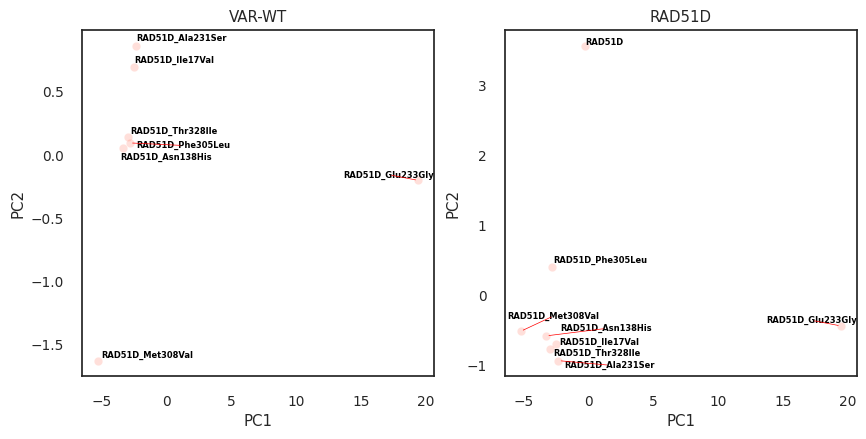

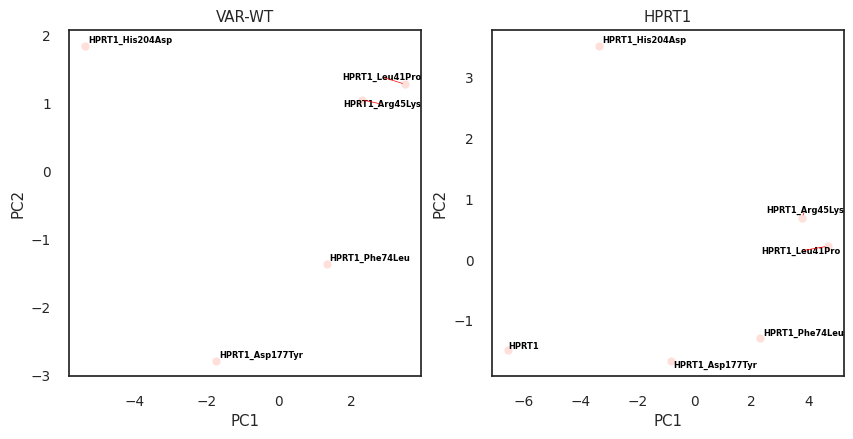

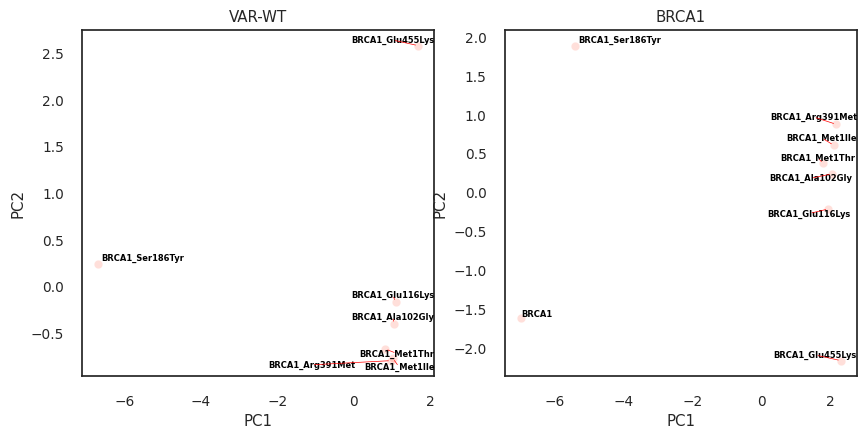

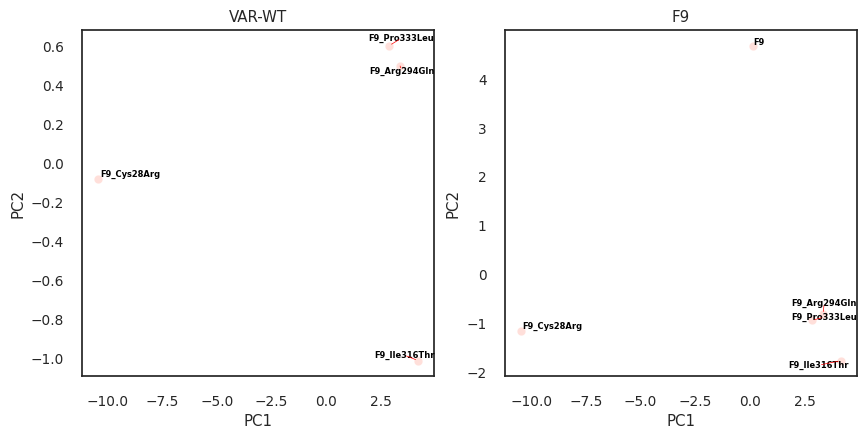

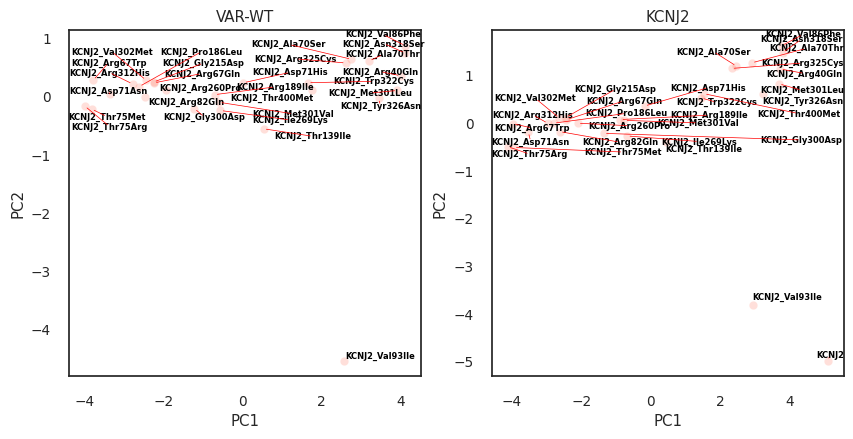

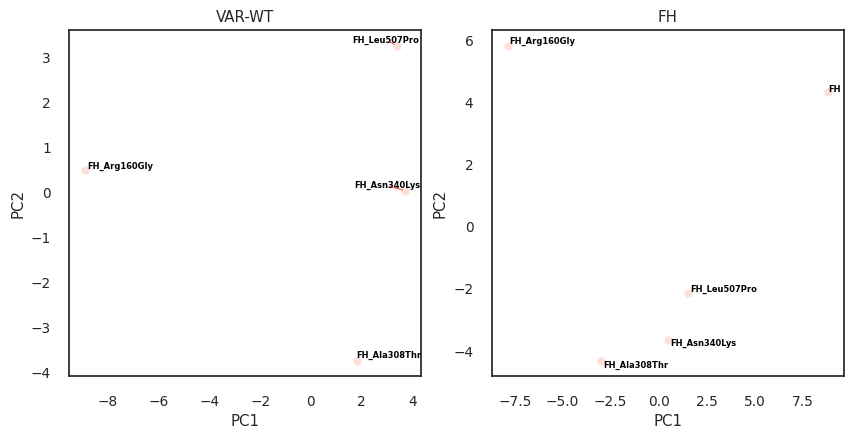

In [127]:
gene_list = ref_var_allele_proc_prof_df.filter(~pl.col("Metadata_gene_allele").str.contains("_"))["Metadata_gene_allele"]
for gene in gene_list:
    gene_df = ref_var_allele_proc_prof_df.filter(pl.col("Metadata_gene_allele").str.contains(gene))
    if gene_df.shape[0] >= 5:
        gene_row = gene_df.filter(~pl.col("Metadata_gene_allele").str.contains("_"))
        var_rows = gene_df.filter(pl.col("Metadata_gene_allele").str.contains("_"))
        var_rows = var_rows.with_columns(
            [pl.col(c) - gene_row[c] for c in var_rows.columns if "Metadata_" not in c]
        )
        # var_rows = pl.concat([
        #     var_rows, gene_row
        # ], how="vertical")
        # display(var_rows)
        # umap_reducer = umap.UMAP(n_components=2, random_state=42, 
        #                        metric='jaccard', n_neighbors=15, min_dist=0.1)
        # X_umap = umap_reducer.fit_transform(var_rows.select([c for c in var_rows.columns if "Metadata_" not in c]).to_numpy())
        
        pca = PCA(n_components=2, random_state=42)
        X_pca = pca.fit_transform(var_rows.select([c for c in var_rows.columns if "Metadata_" not in c]).to_numpy())
        X_pca_orig = pca.fit_transform(gene_df.select([c for c in gene_df.columns if "Metadata_" not in c]).to_numpy())

        umap_df = pd.DataFrame(X_pca_orig, columns=["PC1", "PC2"])
        umap_df["Metadata_main_loc"] = gene_df["Metadata_main_loc"]
        umap_df["Metadata_gene_allele"] = gene_df["Metadata_gene_allele"]
        
        pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
        pca_df["Metadata_main_loc"] = var_rows["Metadata_main_loc"]
        pca_df["Metadata_gene_allele"] = var_rows["Metadata_gene_allele"]
        
        fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
        sns.scatterplot(data=pca_df, x="PC1", y="PC2", #hue="Metadata_main_loc", palette=custom_palette, 
                        ax=axes[0], #style="Metadata_allele_type", hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique()), 
                        color="tomato", alpha=.2,
                        legend=False)
        sns.scatterplot(data=umap_df, x="PC1", y="PC2", #hue="Metadata_main_loc", palette=custom_palette,  
                        ax=axes[1],
                        # style="Metadata_allele_type", hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique())
                        color="tomato", alpha=.2,
                        legend=False)
        texts = []
        for i, label in enumerate(pca_df["Metadata_gene_allele"].to_list()):
            texts.append(axes[0].text(pca_df.iloc[i, 0], pca_df.iloc[i, 1], label, 
                            fontsize=6, fontweight='bold', color='black'))
        adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=axes[0]) ## 

        texts = []
        for i, label in enumerate(umap_df["Metadata_gene_allele"].to_list()):
            texts.append(axes[1].text(umap_df.iloc[i, 0], umap_df.iloc[i, 1], label, 
                            fontsize=6, fontweight='bold', color='black'))
        adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=axes[1]) ## 
        axes[1].set_title(gene)
        axes[0].set_title("VAR-WT")

In [56]:
custom_palette_ = sns.color_palette("colorblind", 10) + \
                 sns.color_palette("Set2", 8) + \
                 sns.color_palette("Dark2", 8) + \
                 sns.color_palette("Pastel1", 9)

# Create palette dictionary with "Unknown" specifically set to grey
unique_locations = sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].unique())
custom_palette = {}

for i, location in enumerate(unique_locations):
    if location == "Unknown":
        custom_palette[location] = '#808080'  # Grey color
    else:
        # Use colors from custom palette, skipping grey colors for other categories
        non_grey_colors = [c for c in custom_palette_ if c not in ['#7f7f7f', '#d9d9d9', '#808080']]
        custom_palette[location] = non_grey_colors[i % len(non_grey_colors)]

Computing UMAP embedding...


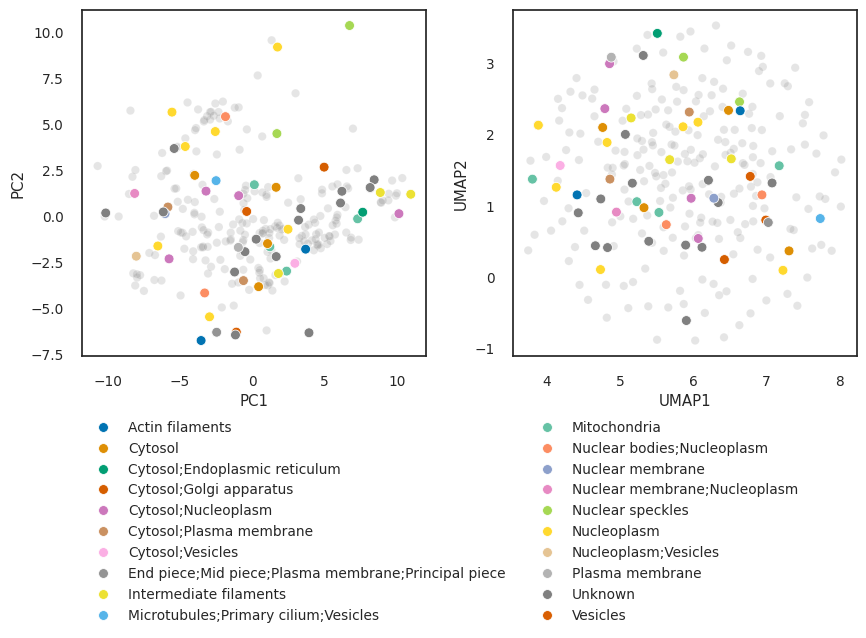

In [65]:
# UMAP - excellent for binary/sparse data
print("Computing UMAP embedding...")
umap_reducer = umap.UMAP(n_components=2, random_state=42, 
                       metric='jaccard', n_neighbors=15, min_dist=0.1)
X_umap = umap_reducer.fit_transform(ref_var_allele_proc_prof_df.select(
    [c for c in ref_var_allele_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(ref_var_allele_proc_prof_df.select(
    [c for c in ref_var_allele_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

umap_df = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_main_loc"] = ref_var_allele_proc_prof_df["Metadata_main_loc"]
umap_df["Metadata_gene_allele"] = ref_var_allele_proc_prof_df["Metadata_gene_allele"]
umap_df["Metadata_allele_type"] = ref_var_allele_proc_prof_df["Metadata_allele_type"]

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Metadata_main_loc"] = ref_var_allele_proc_prof_df["Metadata_main_loc"]
pca_df["Metadata_gene_allele"] = ref_var_allele_proc_prof_df["Metadata_gene_allele"]
pca_df["Metadata_allele_type"] = ref_var_allele_proc_prof_df["Metadata_allele_type"]

fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
sns.scatterplot(data=pca_df[pca_df["Metadata_allele_type"]=="VAR"], x="PC1", y="PC2", hue="Metadata_main_loc", palette=custom_palette, 
                ax=axes[0], #style="Metadata_allele_type", hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique()), 
                color="lightgrey", alpha=.2,
                legend=False)
sns.scatterplot(data=umap_df[umap_df["Metadata_allele_type"]=="VAR"], x="UMAP1", y="UMAP2", hue="Metadata_main_loc", palette=custom_palette,  
                ax=axes[1],
                # style="Metadata_allele_type", hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique())
                color="lightgrey", alpha=.2,
                legend=False)

sns.scatterplot(data=pca_df[pca_df["Metadata_allele_type"]!="VAR"], x="PC1", y="PC2", hue="Metadata_main_loc", palette=custom_palette, 
                ax=axes[0], marker="o", s=50,
                #style="Metadata_allele_type", 
                hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique()), 
                legend=False)
sns.scatterplot(data=umap_df[umap_df["Metadata_allele_type"]!="VAR"], x="UMAP1", y="UMAP2", hue="Metadata_main_loc", palette=custom_palette,  
                ax=axes[1], marker="o", s=50,
                # style="Metadata_allele_type",
                hue_order=sorted(ref_var_allele_proc_prof_df["Metadata_main_loc"].drop_nulls().unique()))
axes[1].legend(bbox_to_anchor=(-0.2, -0.15), ncol=2, loc="upper center")
plt.subplots_adjust(wspace=.25)

In [104]:
feat_df_select = feat_df.filter(
    pl.col("cp_feature").is_in([c for c in ref_var_allele_int_featselect_prof_df.columns if FEAT in c])
).fill_null(0)
feat_df_select_hits = feat_df_select.select(pl.col(["cp_feature"]+imaging_summary_clinvar_hits["gene_allele"].to_list()))

# feat_df_select_hits = feat_df_select_hits.filter(
#     pl.mean_horizontal([c for c in feat_df_select_hits.columns if c != "cp_feature"]) >= 5e-3
# )
feat_df_select_hits

cp_feature,SMARCB1_Pro48Leu,MVK_Leu265Pro,KRT8_Arg454Cys,DES_Asn342Asp,LITAF_Pro84Leu,SMAD3_Cys109Tyr,MLH1_Lys670Arg,KCNJ2_Asp71His,GFAP_Lys236Thr,MLH1_Ala29Gly,KCNJ2_Met301Leu,GFAP_Arg79Ser,MLH1_Pro640Ser,KCNJ2_Val93Ile,HPRT1_Arg45Lys,GFAP_Arg239Leu,KCNJ2_Thr75Arg,SFTPC_Leu188Gln,GFAP_Asn77Ser,FBP1_Phe194Ser,FXN_Trp173Gly,GFAP_Arg88Cys,KCNJ2_Gly300Asp,KCNJ2_Asp71Asn,SFTPA2_Gly231Val,STXBP1_Arg406Leu,STXBP1_Thr419Met,KCNJ2_Thr139Ile,STXBP1_Gly417Asp,LITAF_Trp116Gly,STXBP1_Met443Arg,STXBP1_Val451Ile,MLH1_Gln701His,NR0B1_Arg267Pro,STXBP1_Leu256Pro,AGXT_Gly116Arg,…,BRCA1_Met1Ile,RET_Arg330Gln,ZC4H2_Arg18Lys,SDHD_His102Leu,RAD51D_Thr328Ile,LMNA_Arg377Leu,SOS2_Val869Ile,FH_Arg160Gly,FH_Leu507Pro,RHO_Arg135Trp,RHO_Pro267Thr,F9_Pro333Leu,ZC4H2_Leu66His,RAD51D_Ile17Val,BRCA1_Arg391Met,RAF1_Gly361Ala,BRCA1_Ser186Tyr,FH_Asn340Lys,CTCF_Arg567Trp,KRAS_Phe156Leu,RAD51D_Phe305Leu,F9_Arg294Gln,BRCA1_Glu116Lys,FH_Ala308Thr,BRCA1_Met1Thr,RAD51D_Ala231Ser,BRCA1_Glu455Lys,F9_Cys28Arg,F9_Ile316Thr,RHO_Asp190Gly,BRIP1_Thr266Lys,RAD51D_Glu233Gly,RAD51D_Asn138His,RHO_Cys110Tyr,SHOC2_Ser2Gly,BRCA1_Ala102Gly,RAD51D_Met308Val
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Cells_Correlation_RWC_Mito_GFP""",0.004104,0.015118,0.007607,0.012526,0.006805,0.01013,0.0,0.006794,0.010473,0.0,0.00755,0.010529,0.0,0.005254,0.006274,0.012499,0.082718,0.146456,0.008443,0.016932,0.004775,0.007945,0.075306,0.005831,0.019478,0.0,0.0,0.063405,0.0,0.007383,0.0,0.0,0.0,0.006766,0.0,0.016917,…,0.039128,0.02098,0.011272,0.005133,0.007975,0.002032,0.027679,0.002574,0.011368,0.007759,0.008842,0.013569,0.008592,0.009245,0.033195,0.01475,0.035461,0.007365,0.004115,0.004367,0.010614,0.009754,0.014104,0.008235,0.031653,0.008179,0.00621,0.014336,0.011355,0.002575,0.004272,0.010562,0.009355,0.003498,0.015597,0.027198,0.007289
"""Nuclei_Correlation_K_GFP_AGP""",0.010761,0.0053,0.009562,0.016377,0.00385,0.007634,0.018528,0.004142,0.007018,0.020791,0.005301,0.007143,0.015652,0.007521,0.003655,0.006945,0.008675,0.00774,0.005666,0.099258,0.01704,0.00577,0.011034,0.024213,0.008191,0.011428,0.013347,0.010426,0.010728,0.006068,0.008178,0.011431,0.009651,0.003874,0.010224,0.023517,…,0.00586,0.012385,0.025654,0.006441,0.00763,0.002597,0.02714,0.003212,0.002357,0.008693,0.012794,0.004267,0.005891,0.005369,0.006156,0.010196,0.012367,0.009129,0.004078,0.007197,0.011068,0.008906,0.008648,0.006321,0.006144,0.005533,0.004236,0.009507,0.004964,0.014041,0.00999,0.004642,0.008274,0.006814,0.009003,0.004924,0.009266
"""Cytoplasm_Intensity_MaxIntensi…",0.003882,0.035819,0.011329,0.009624,0.121668,0.02223,0.0,0.004825,0.007795,0.0,0.00528,0.009608,0.0,0.007854,0.005909,0.015794,0.007326,0.003903,0.009053,0.186776,0.007165,0.007359,0.008203,0.006028,0.01182,0.0,0.0,0.007955,0.0,0.011157,0.0,0.0,0.0,0.043091,0.0,0.020743,…,0.005942,0.004776,0.081115,0.003879,0.056354,0.004205,0.065638,0.009368,0.037984,0.016376,0.023724,0.004176,0.017931,0.041862,0.006258,0.048582,0.004288,0.096666,0.004351,0.00786,0.036992,0.009422,0.04839,0.061352,0.006676,0.052535,0.017207,0.082453,0.007127,0.008143,0.004583,0.018769,0.060725,0.006159,0.028845,0.027416,0.078933
"""Cells_RadialDistribution_MeanF…",0.008969,0.019083,0.005332,0.005668,0.004224,0.017721,0.007796,0.009876,0.007076,0.008806,0.007105,0.006685,0.008084,0.004135,0.007144,0.008215,0.004879,0.00413,0.008674,0.012934,0.004045,0.006435,0.00415,0.004454,0.004657,0.005622,0.035268,0.003517,0.040252,0.003187,0.003915,0.028238,0.004334,0.005484,0.008543,0.008494,…,0.005985,0.004914,0.004589,0.007826,0.00824,0.007724,0.002826,0.012565,0.00684,0.011762,0.008835,0.004942,0.005795,0.005157,0.009492,0.004765,0.004504,0.004061,0.005435,0.003085,0.007727,0.002976,0.005348,0.00414,0.006676,0.005748,0.003155,0.005835,0.00499,0.

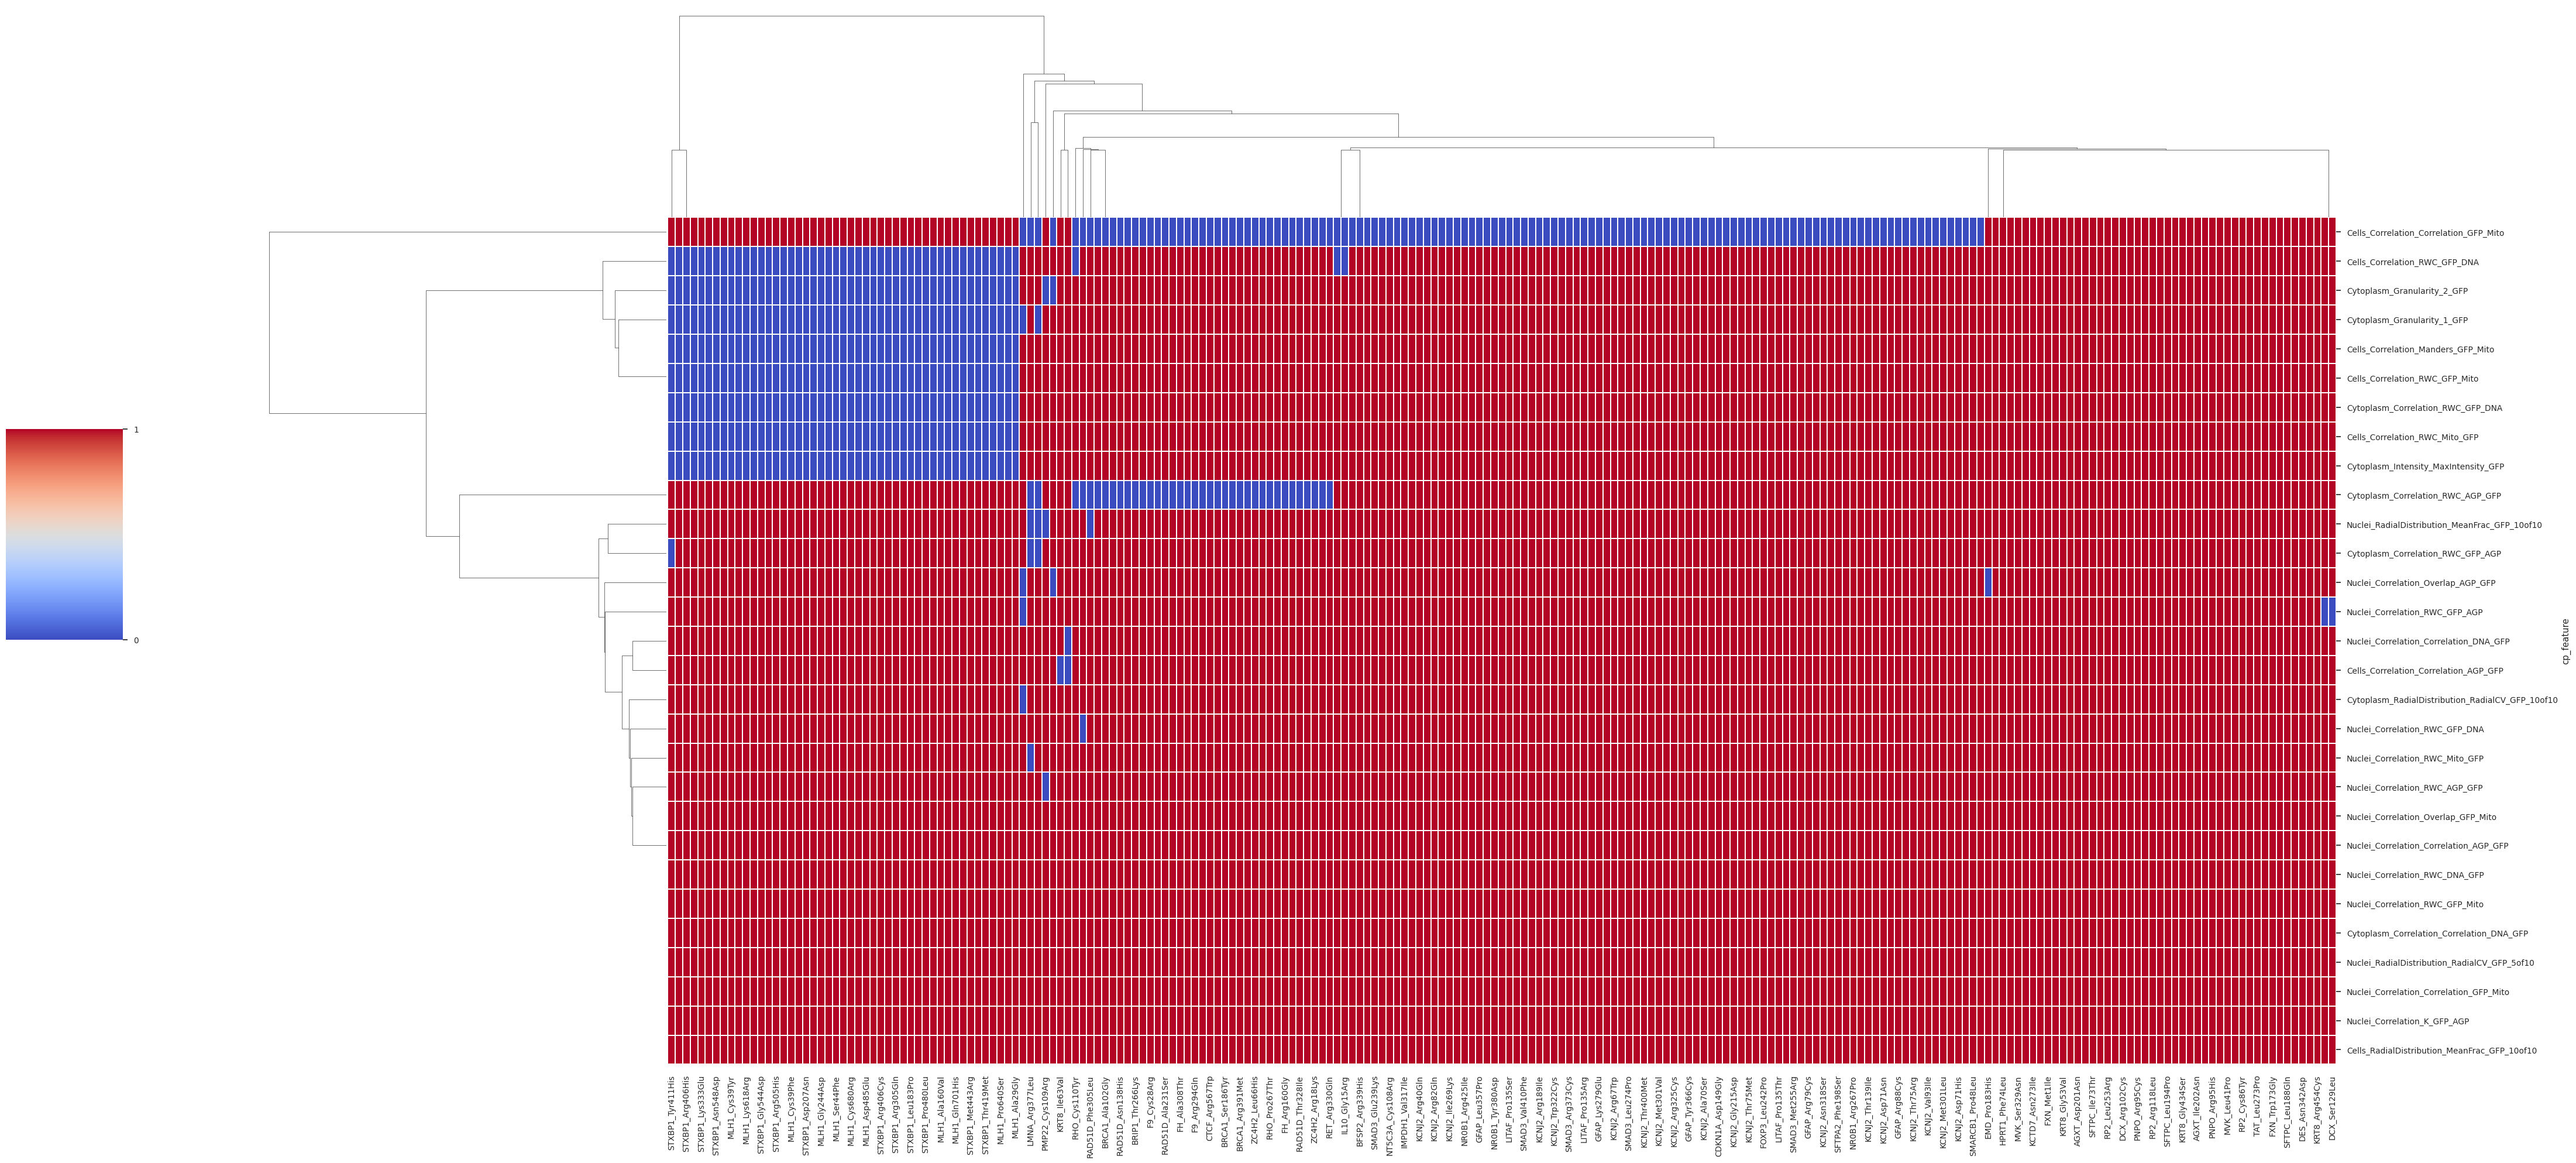

In [80]:
sns.clustermap(
    data=feat_df_select_hits.with_columns(
        pl.col([c for c in feat_df_select_hits.columns if c != "cp_feature"]).map_elements(lambda x: 1 if x > 0 else 0)
    ).to_pandas().set_index("cp_feature"),
    figsize=(40, 20),
    cmap="coolwarm",
    # square=True,
    # ax=ax,
    linewidths=0.2,         # <-- width of the cell borders
    linecolor='white',       # <-- color of the borders
    col_cluster=True,
    cbar_pos=(-0.1, 0.45, 0.05, 0.18),
    cbar_kws={
        "ticks": [0, 1],        # ← only show 0 and 1
        "format": "%d",         # integer formatting
    }
)

In [105]:
misloc_var_diff_wt = pl.DataFrame()
for allele in tqdm(imaging_summary_clinvar_hits["gene_allele"]):
    gene_row = ref_var_allele_int_featselect_prof_df.filter(pl.col("Metadata_gene_allele")==allele.split("_")[0])
    var_rows = ref_var_allele_int_featselect_prof_df.filter(pl.col("Metadata_gene_allele")==allele)
    var_rows = var_rows.with_columns(
        [pl.col(c) - gene_row[c] for c in feat_df_select_hits["cp_feature"]]
    )
    # print(var_rows)
    misloc_var_diff_wt = pl.concat([misloc_var_diff_wt, 
                                    var_rows.select(["Metadata_gene_allele"]+feat_df_select_hits["cp_feature"].to_list())])
# misloc_var_diff_wt.write_csv("../../3_outputs/mislocalized_variant_cp_featselect_diff_wrt_ref.csv")

100%|██████████| 223/223 [00:04<00:00, 46.76it/s]


In [88]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score
from umap import UMAP
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from tqdm import tqdm

custom_palette_ = sns.color_palette("colorblind", 10) + \
                  sns.color_palette("Set2", 8) + \
                  sns.color_palette("Dark2", 8) + \
                  sns.color_palette("Pastel1", 9) + \
                  sns.color_palette("husl", 10)

# ------------------------------------------------------------------
# Load the CSV
# ------------------------------------------------------------------
df = pd.read_csv("../../3_outputs/mislocalized_variant_cp_featselect_diff_wrt_ref.csv", index_col=0)
X  = df.values                 # rows = variants, cols = features
variant_names = df.index
feat_names = df.columns
Xz = StandardScaler().fit_transform(X)

# 2. helper: cluster with *exactly* >= min_size members
# ----------------------------------------------------------------------------
def ward_no_singletons(k, data, min_size=2):
    """Return labels for k clusters, guaranteeing no singletons."""
    while True:
        labels = AgglomerativeClustering(
            n_clusters=k, linkage='average', 
            affinity='cosine').fit_predict(data)
        sizes = np.bincount(labels)
        if np.all(sizes >= min_size):
            return labels
        k -= 1               # reduce k until condition met
        if k < 2:            # safety net
            raise ValueError("Cannot reach k≥2 without singletons.")

max_k = 50
rng = np.random.RandomState(42)
n_boot = 100
consensus = np.zeros((max_k-1, n_boot))   # k vs bootstrap ARI


for b in tqdm(range(n_boot)):
    idx = rng.choice(len(Xz), size=int(0.8*len(Xz)), replace=False)
    ref = ward_no_singletons(2, Xz[idx])      # reference for b=0
    for ki, k in enumerate(range(2, max_k+1), 0):
        labels = ward_no_singletons(k, Xz[idx])
        consensus[ki, b] = adjusted_rand_score(ref, labels)


mean_stab = consensus.mean(axis=1)
opt_k = np.argmax(mean_stab) + 2        # k starts at 2
print("Optimal k (max consensus stability) =", opt_k)

# ----------------------------------------------------------------------------
# 4. final clustering on full data
# ----------------------------------------------------------------------------
final_labels = ward_no_singletons(opt_k, Xz)
cluster_df = pd.Series(final_labels, index=variant_names, name='cluster')

100%|██████████| 100/100 [01:08<00:00,  1.46it/s]

Optimal k (max consensus stability) = 2


In [129]:
clusterer = AgglomerativeClustering(n_clusters=k_star, linkage='average', affinity='cosine')
labels = clusterer.fit_predict(X_scaled)

# Build a DataFrame for downstream plotting
cluster_df = pd.DataFrame({'variant': variant_names, 'cluster': labels})

pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
umap_2d = UMAP(n_components=2, random_state=42, n_jobs=1).fit_transform(X_scaled)

pca_df = pd.DataFrame(pca, columns=["PC1", "PC2"])
pca_df["Cluster"] = labels
pca_df["gene_allele"] = variant_names

umap_df = pd.DataFrame(umap_2d, columns=["UMAP1", "UMAP2"])
umap_df["Cluster"] = labels
umap_df["gene_allele"] = variant_names

pca_df = pl.DataFrame(pca_df).join(
    imaging_summary_clinvar_hits.select(["gene_allele", "clinvar_clnsig_clean"]),
    on="gene_allele"
).to_pandas()
umap_df = pl.DataFrame(umap_df).join(
    imaging_summary_clinvar_hits.select(["gene_allele", "clinvar_clnsig_clean"]),
    on="gene_allele"
).to_pandas()

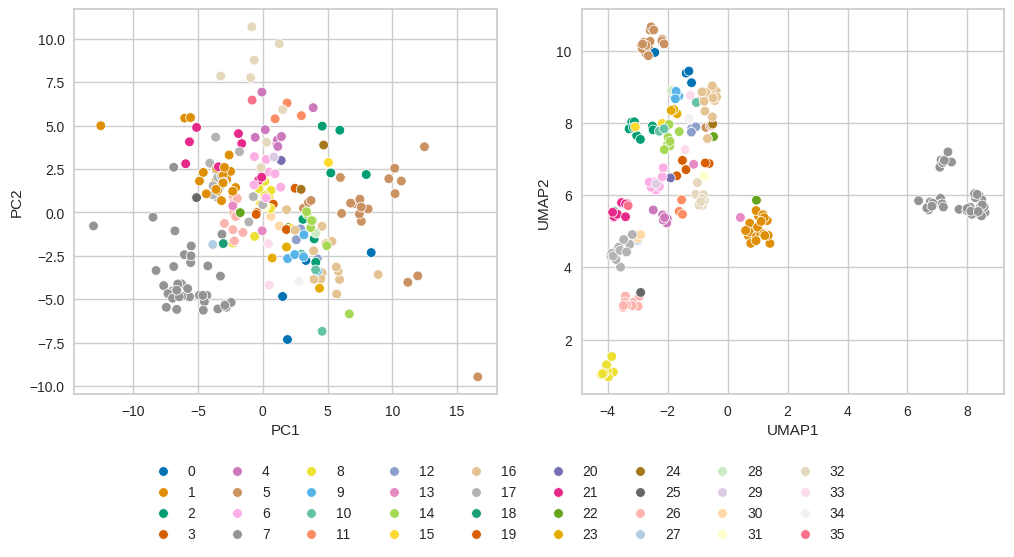

In [82]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    ax=ax[0],
    legend=False,
    palette=custom_palette_
)
sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="Cluster",
    ax=ax[1],
    legend=True,
    palette=custom_palette_
)
ax[1].legend(bbox_to_anchor=(-0.2, -0.15), ncol=9, loc="upper center")
plt.show()

In [97]:
from scipy.cluster.hierarchy import optimal_leaf_ordering

# Compute linkage for pretty ordering
link = linkage(X_scaled, method='average', metric="cosine")
# 2. apply optimal leaf ordering
link_olo = optimal_leaf_ordering(link, X_scaled)

X_scaled_df = pd.DataFrame(X_scaled, index=variant_names, columns=feat_names).T

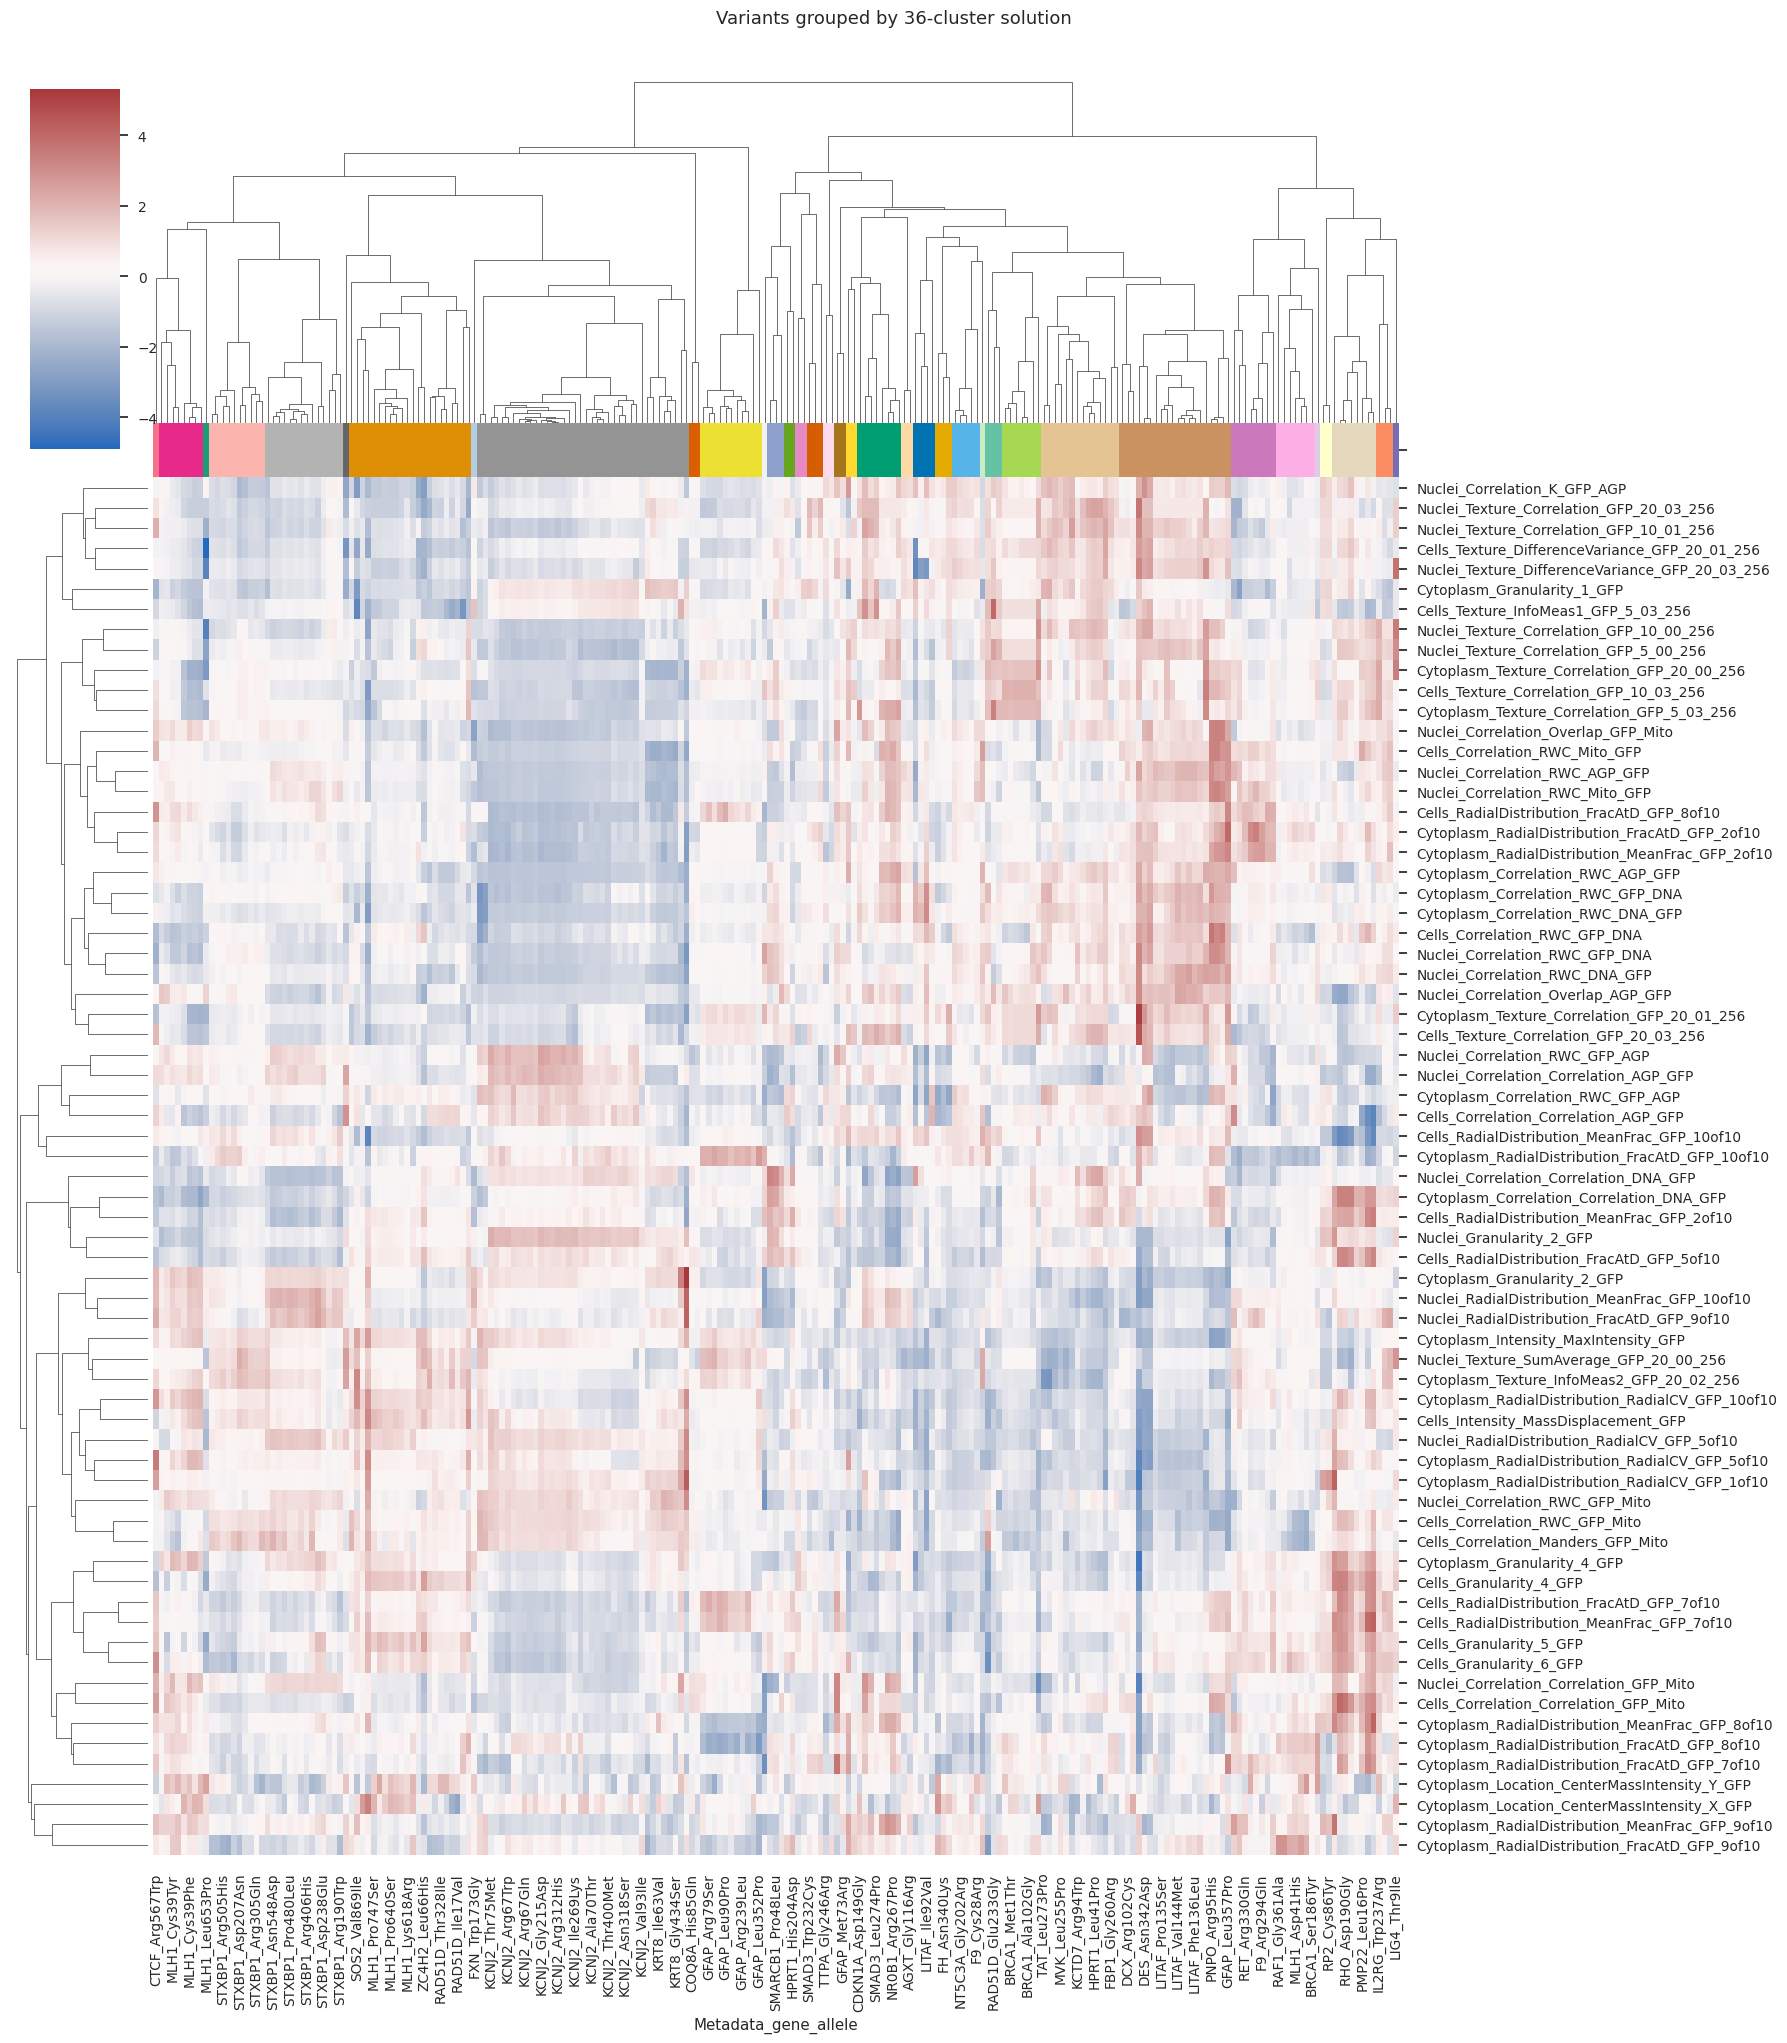

In [98]:
sns.clustermap(
    X_scaled_df,
    row_cluster=True,
    col_linkage=link_olo,
    z_score=0,
    cmap='vlag',
    col_colors=pd.Series(labels, index=variant_names).map(
        {i: custom_palette_[i] for i in range(k_star)}),
    dendrogram_ratio=(.1, .2),
    figsize=(18, 20),
)
plt.suptitle(f"Variants grouped by {k_star}-cluster solution", y=1.02)
plt.show()

<ipython-input-134-e2361cfb03d1>:13: UserWarning: The palette list has more values (45) than needed (4), which may not be intended.
  sns.scatterplot(
<ipython-input-134-e2361cfb03d1>:43: UserWarning: The palette list has more values (45) than needed (4), which may not be intended.
  sns.scatterplot(


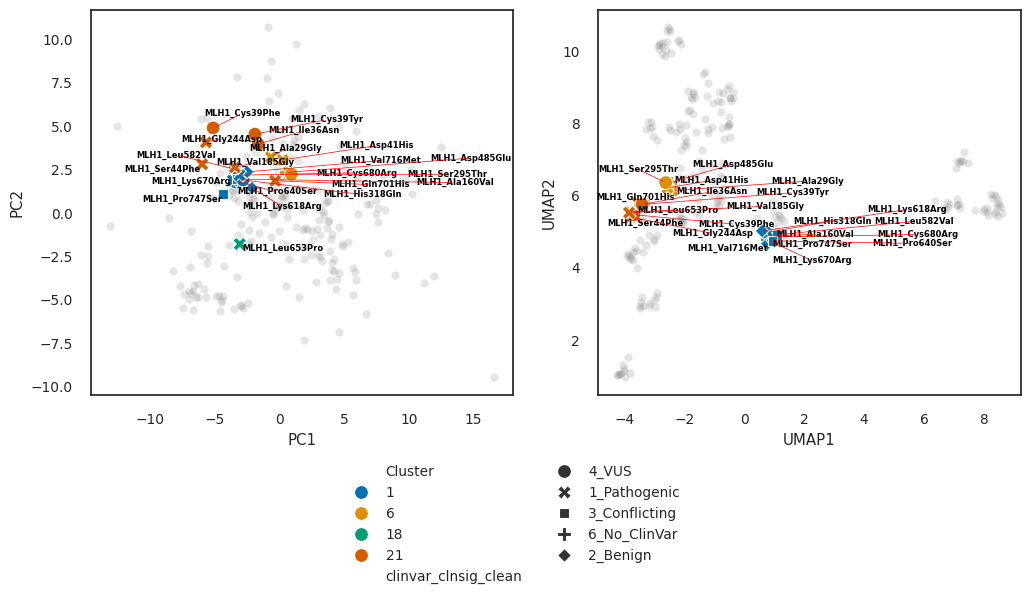

In [134]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    # hue="Cluster",
    color="grey",
    ax=ax[0],
    legend=False,
    alpha=.2,
    # palette=custom_palette_
)
sns.scatterplot(
    data=pca_df[pca_df["gene_allele"].str.contains("MLH1")],
    x="PC1",
    y="PC2",
    hue="Cluster",
    ax=ax[0],
    legend=False,
    palette=custom_palette_,
    style="clinvar_clnsig_clean",
    s=100
)
texts = []
for i, label in enumerate(pca_df[pca_df["gene_allele"].str.contains("MLH1")]["gene_allele"].to_list()):
    texts.append(ax[0].text(pca_df[pca_df["gene_allele"].str.contains("MLH1")].iloc[i, 0], 
                              pca_df[pca_df["gene_allele"].str.contains("MLH1")].iloc[i, 1], 
                              label, 
                    fontsize=6, fontweight='bold', color='black'))
adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[0]) ## 

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    # hue="Cluster",
    color="grey",
    ax=ax[1],
    legend=False,
    alpha=.2,
    # palette=custom_palette_
)
sns.scatterplot(
    data=umap_df[umap_df["gene_allele"].str.contains("MLH1")],
    x="UMAP1",
    y="UMAP2",
    hue="Cluster",
    ax=ax[1],
    legend=True,
    style="clinvar_clnsig_clean",
    palette=custom_palette_,
    s=100
)

texts = []
for i, label in enumerate(umap_df[umap_df["gene_allele"].str.contains("MLH1")]["gene_allele"].to_list()):
    texts.append(ax[1].text(umap_df[umap_df["gene_allele"].str.contains("MLH1")].iloc[i, 0], 
                              umap_df[umap_df["gene_allele"].str.contains("MLH1")].iloc[i, 1], label, 
                    fontsize=6, fontweight='bold', color='black'))
adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[1]) ## 

ax[1].legend(bbox_to_anchor=(-0.2, -0.15), ncol=2, loc="upper center")
plt.show()

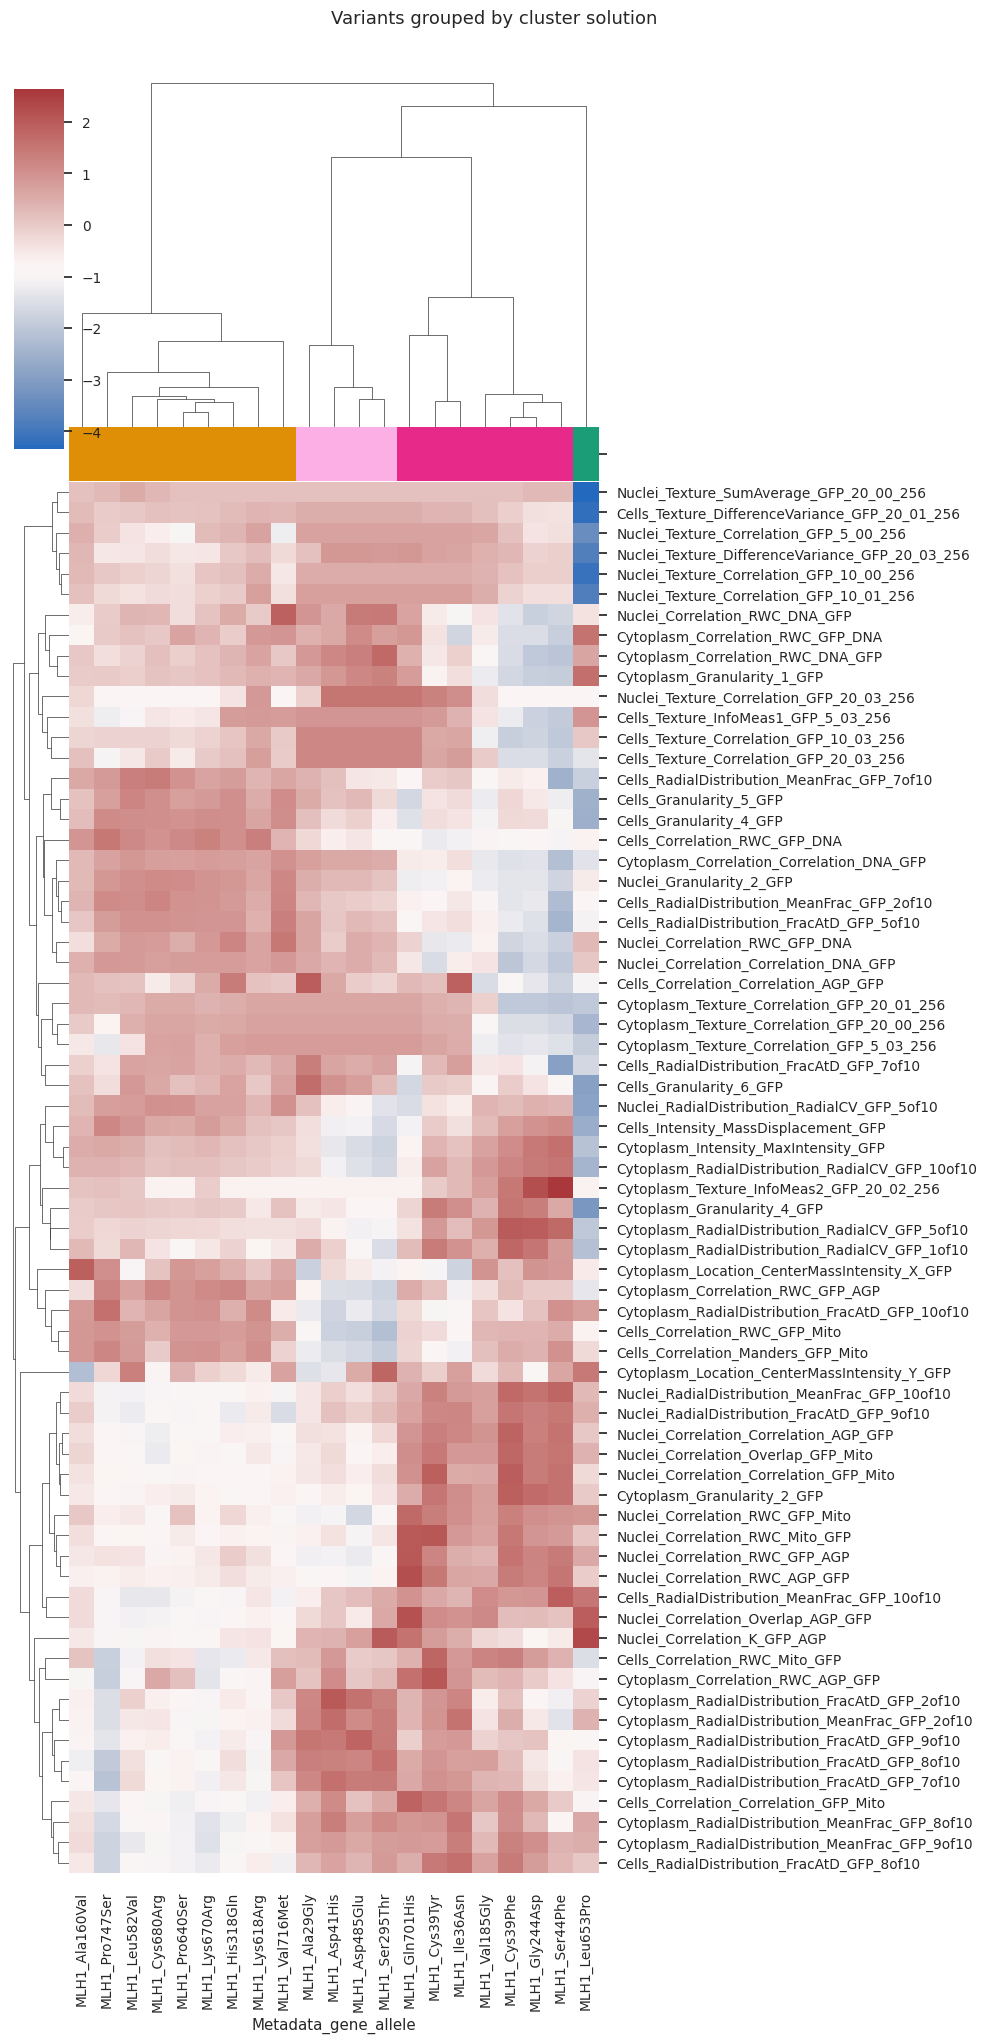

In [121]:
# Compute linkage for pretty ordering
mlh1_var = [idx for idx in X_scaled_df.columns if "MLH1" in idx]

link = linkage(X_scaled_df.loc[:,mlh1_var].T, method='average', metric="cosine")
# 2. apply optimal leaf ordering
link_olo = optimal_leaf_ordering(link, X_scaled_df.loc[:,mlh1_var].T)
labels = umap_df[umap_df["gene_allele"].str.contains("MLH1")]["Cluster"].values
var_labels = umap_df[umap_df["gene_allele"].str.contains("MLH1")]["gene_allele"].values

sns.clustermap(
    X_scaled_df.loc[:,mlh1_var],
    row_cluster=True,
    col_linkage=link_olo,
    z_score=0,
    cmap='vlag',
    col_colors=pd.Series(labels, index=var_labels).map(
        {i: custom_palette_[i] for i in range(k_star)}),
    dendrogram_ratio=(.1, .2),
    figsize=(10, 20),
)
plt.suptitle(f"Variants grouped by cluster solution", y=1.02)
plt.show()

In Cell Painting assays analyzed with CellProfiler, the feature called Cytoplasm_Granularity refers to the texture of the staining pattern within the cytoplasm, specifically measuring how “grainy” or “speckled” the signal is at different spatial scales.

Here’s a breakdown:

__What it Measures:__

* Granularity is a texture feature that captures the size and frequency of bright spots (or granules) in the image at multiple spatial scales.

* It’s based on morphological operations (often using granulometry) to assess how much image content (signal) is removed by a series of opening operations with structuring elements of increasing sizes.

* High granularity indicates numerous small, bright objects in the cytoplasm (e.g., vesicles, organelles).

* Low granularity implies a more uniform or diffuse staining pattern.

__How It Works in CellProfiler:__

* For each cytoplasm region, CellProfiler computes how much of the signal is lost when applying filters that remove structures below certain sizes.

* The result is a series of granularity features, each corresponding to a different scale (e.g., Cytoplasm_Granularity_1, Cytoplasm_Granularity_2, …).

* These scales correspond to different object sizes: smaller numbers = finer textures; larger numbers = coarser granules.

__In Cell Painting:__

* Different dyes highlight organelles like mitochondria, endoplasmic reticulum, Golgi, etc.

* Cytoplasm_Granularity can reflect changes in organelle morphology or distribution due to chemical or genetic perturbations.

* It’s used as a phenotypic descriptor in high-content screening and profiling.